# Importando Bibliotecas

In [113]:
# Seleção de diretórios
import os

# Carregamento de dados
from joblib import load, dump

# Processamento de dados
import numpy as np
import pandas as pd

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Funções de clustering
from src.clustering import Clustering

# Cross Validation and Grid Search

In [114]:
# Modelos de aprendizado de máquina
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score, StratifiedKFold

# Importando Dados

In [115]:
os.listdir()

['00-divisão_dados_2026-07-14.ipynb',
 '01-aula-02_objetivos_2026-07-14.ipynb',
 '02-aula-04_aquisição_2026-07-14.ipynb',
 '03-aula-05_01-dados_2026-07-14.ipynb',
 '03-aula-05_02-cluster_2026-07-14.ipynb',
 '03-aula-05_03-classif_2026-07-14.ipynb',
 '03-aula-05_04-regressão_2026-07-14.ipynb',
 '03-aula-05_05_analise_2026-07-14.ipynb',
 '04-aula-06-divisão de dados_2026-07-14.ipynb',
 '05-aula-07-estruturação_2025-12-03.ipynb',
 '07-aula-09-01-treinamento_feat_selection_2026-07-26.ipynb',
 '07-aula-09-02-treinamento_cluster_2026-07-26.ipynb',
 '07-aula-09-03-treinamento_classif_2026-07-28.ipynb',
 '07-aula-09-04-treinamento_regressão_2026-07-28.ipynb',
 'data',
 'df_projeto_sem_nan',
 'df_trabalho_X_test',
 'df_trabalho_X_train',
 'df_trabalho_X_valid',
 'df_trabalho_y_test',
 'df_trabalho_y_train',
 'df_trabalho_y_valid',
 'Metricas Agglomerative',
 'Metricas DBscan',
 'Metricas Kmeans',
 'SMOTE.ipynb',
 'src',
 'Treinamento_Classificacao_SofiaFeronato.ipynb',
 'Treinamento_Clusterizac

In [116]:
# Importando os dados de treino
df_train = pd.concat(
    [
        load("./df_trabalho_X_train"),
        load("./df_trabalho_y_train"),
    ],
    axis=1,
)
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
541,-6.605859,587.422573,861.125119,1.728509,True,False,False,True,False,True,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,True,False,False,True,False,True,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,False,True,True,False,False,True,leucemia
422,-4.197952,537.954188,889.391214,1.574182,True,False,False,True,False,True,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,False,True,True,False,False,True,leucemia


In [117]:
df_train_num = df_train.select_dtypes(include = 'number')

In [118]:
df_train_num.columns

Index(['CD34_log', 'Lin_B', 'Lin_T', 'PPD_log'], dtype='object')

In [119]:
df_train_classe = df_train[['classe']]

In [120]:
df_train = pd.concat([df_train_num,df_train_classe],axis=1)

In [121]:
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,classe
541,-6.605859,587.422573,861.125119,1.728509,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,leucemia
422,-4.197952,537.954188,889.391214,1.574182,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,leucemia


In [122]:
df_train_classe = df_train['classe']

# Validação cruzada e busca de hiperparâmetros

## K-means

### Treino

In [123]:
# Definindo um objeto de clustering com os dados de treino
#retiramos as categoricas para a analise grafica (FOXP3_A e FOXP3_N, Igs_A e Igs_B, citoc_A e citoc_B)    
# ["FOXP3_Normal", "FOXP3_Alterado"],
#    ["Igs_Baixo", "Igs_Alto"],
#    ["citoc_Baixo", "citoc_Alto"]

nome_modelo = "kmeans"
bivariadas = [
    ["CD34_log", "Lin_B"],
    ["PPD_log", "Lin_T"],
]
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[1][0], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 1, 1, 1, 1], dtype=int32)

> Análise gráfica das combinações de variáveis

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5624

Silhouette Score -> 0.554
Calinski Harabasz Score -> 846.333
Davies Bouldin Score -> 0.784
Adjusted Rand Score -> 0.306
Adjusted Mutual Info Score -> 0.49


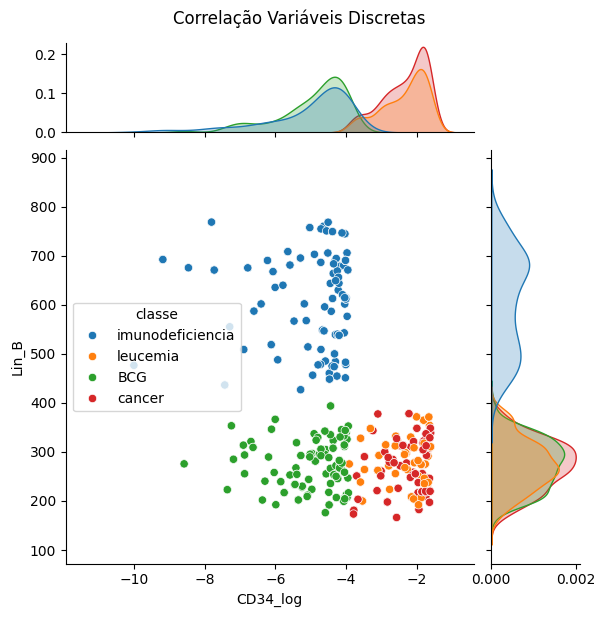

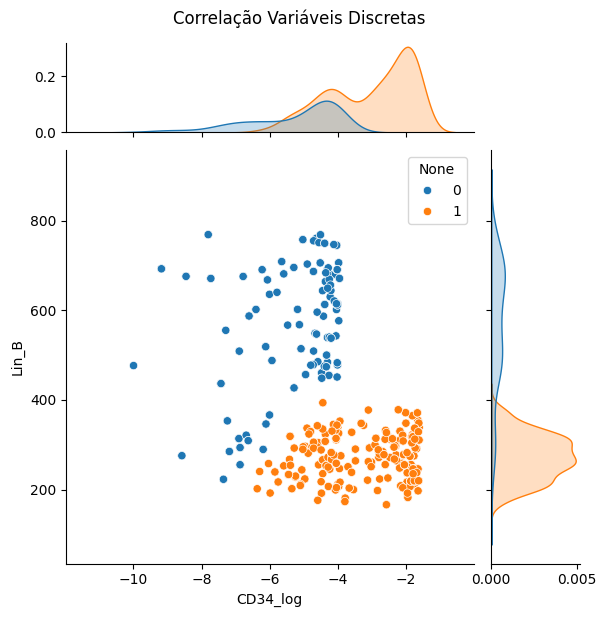

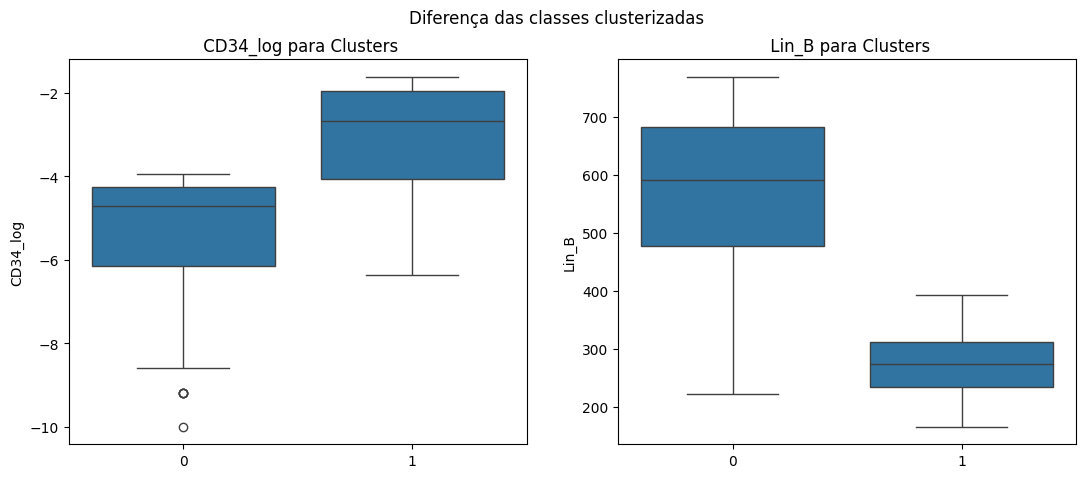

In [124]:
#CD34_log e Lin_B IDENTIFICA 2 GRUPOS - RETIRAR
i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5366

Silhouette Score -> 0.536
Calinski Harabasz Score -> 937.362
Davies Bouldin Score -> 0.768
Adjusted Rand Score -> 0.329
Adjusted Mutual Info Score -> 0.449


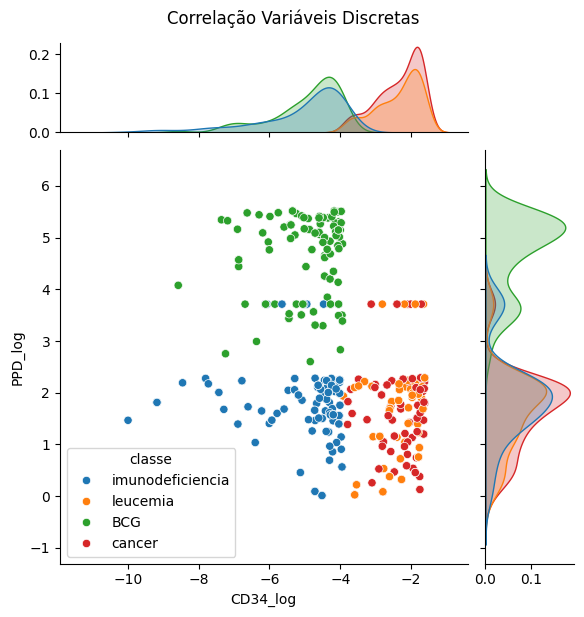

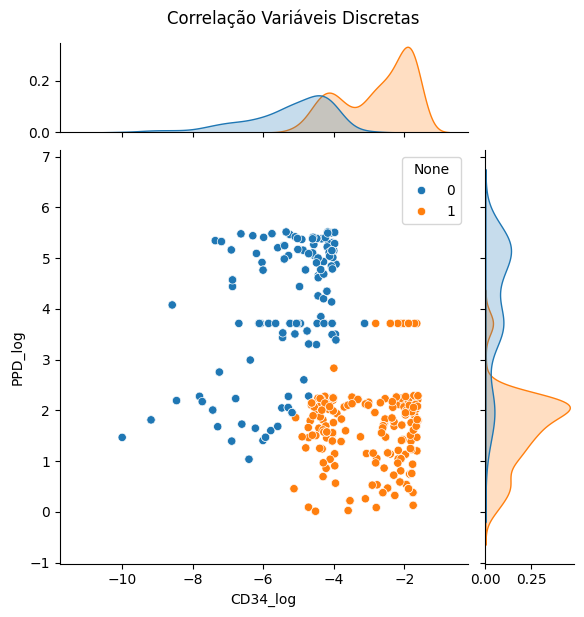

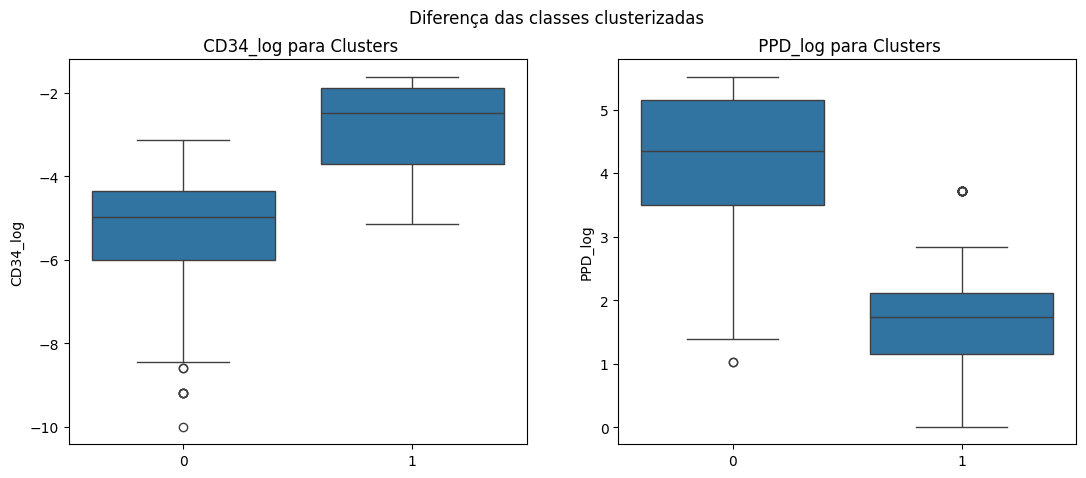

In [125]:
#CD34_log e   PPD_log  IDENTIFICA 2 GRUPOS - RETIRAR
i = bivariadas[0][0]
j = bivariadas[1][0]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5654

Silhouette Score -> 0.565
Calinski Harabasz Score -> 1024.61
Davies Bouldin Score -> 0.633
Adjusted Rand Score -> 0.67
Adjusted Mutual Info Score -> 0.788


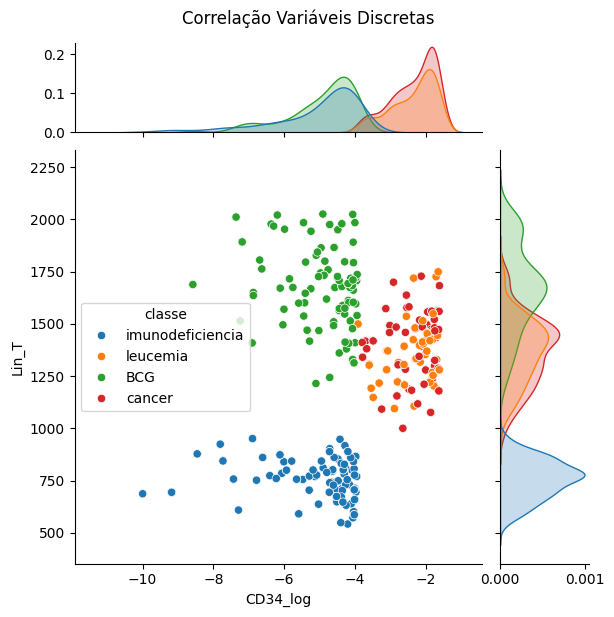

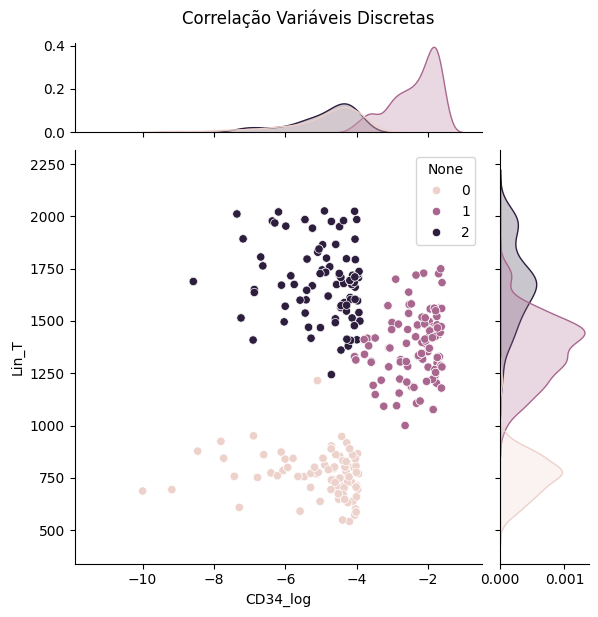

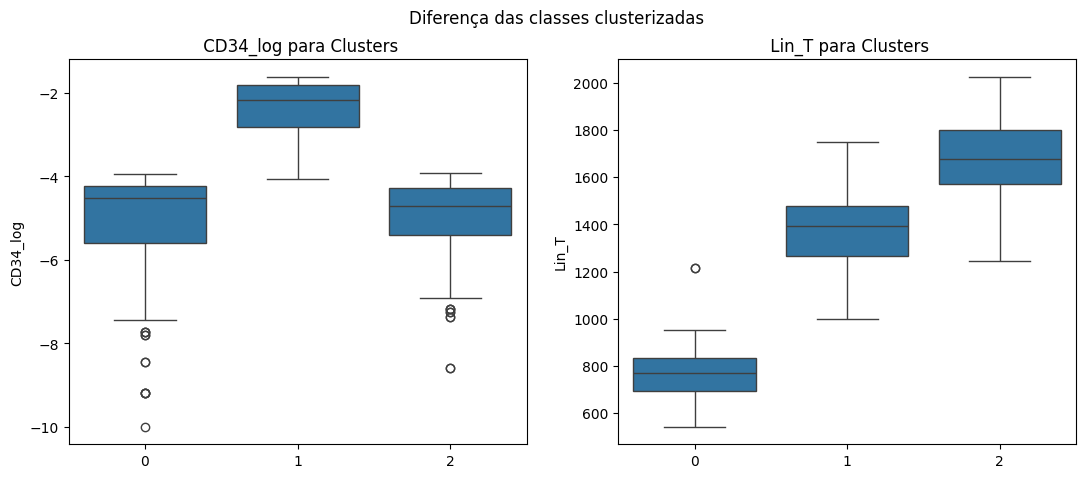

In [126]:
#CD34_log e Lin_T    IDENTIFICA 3 GRUPOS 
i = bivariadas[0][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'random', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5508

Silhouette Score -> 0.553
Calinski Harabasz Score -> 1249.917
Davies Bouldin Score -> 0.619
Adjusted Rand Score -> 0.611
Adjusted Mutual Info Score -> 0.671


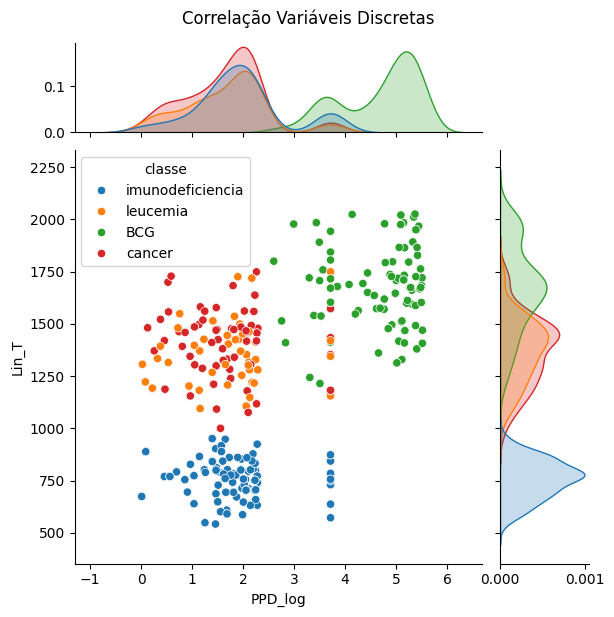

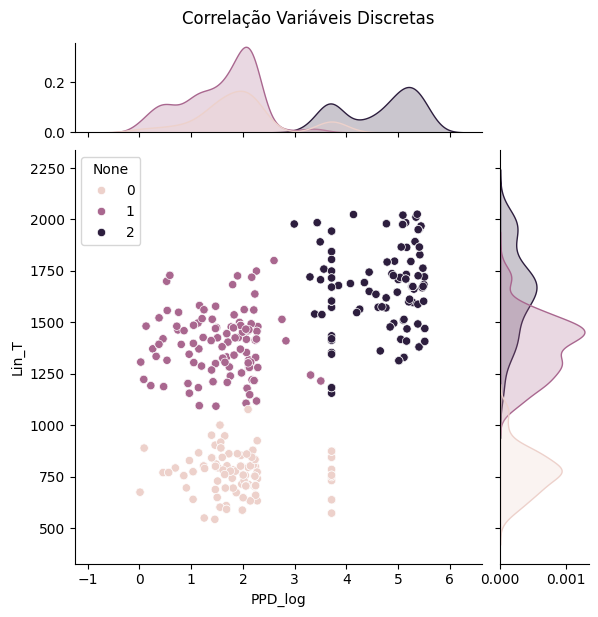

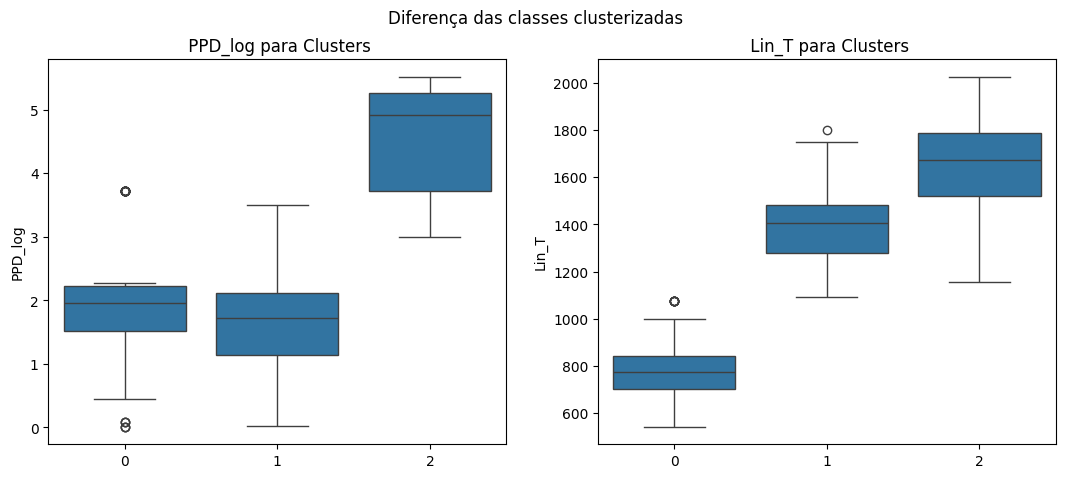

In [127]:
#Lin_T e PPD_log   IDENTIFICA 3 GRUPOS 
i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5366

Silhouette Score -> 0.536
Calinski Harabasz Score -> 937.362
Davies Bouldin Score -> 0.768
Adjusted Rand Score -> 0.329
Adjusted Mutual Info Score -> 0.449


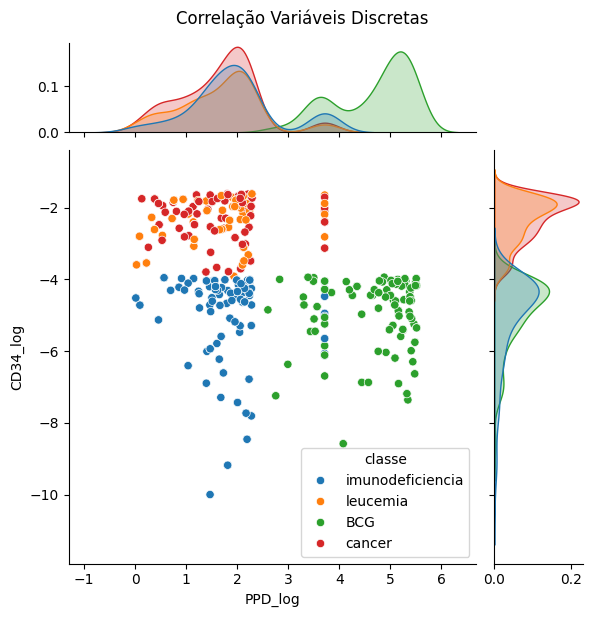

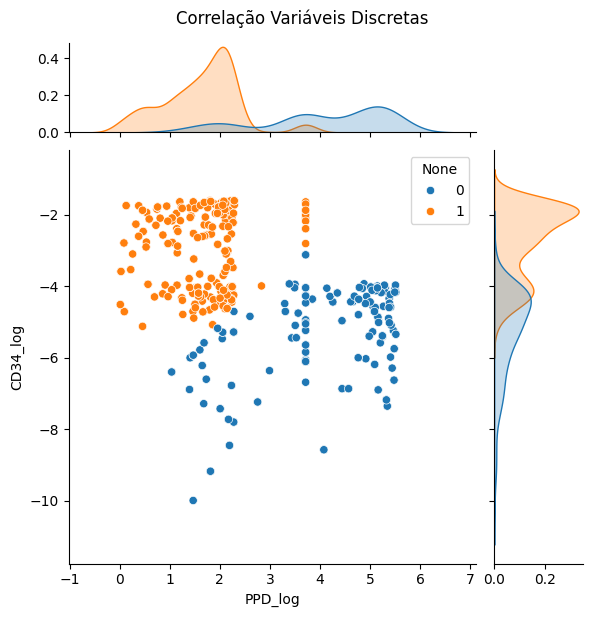

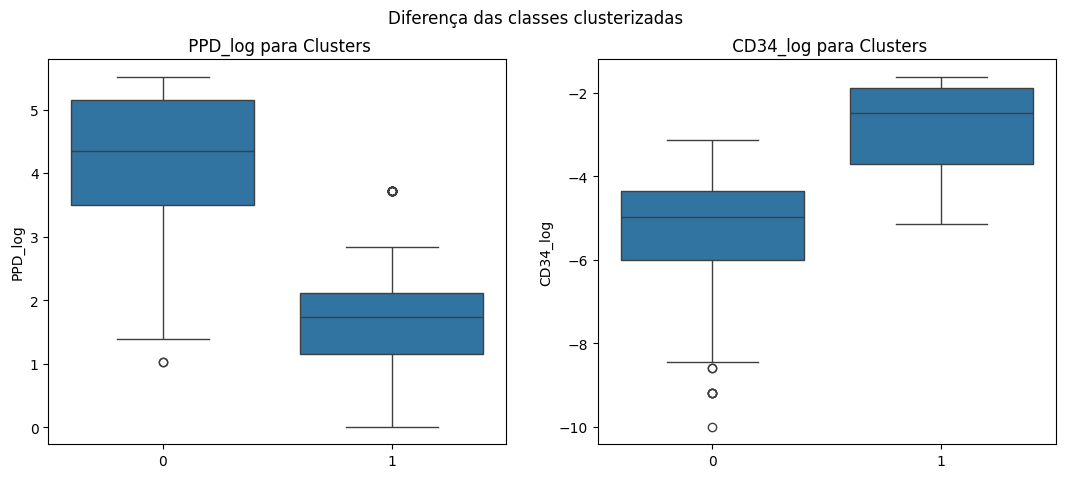

In [128]:
#CD34_log e PPD_log   IDENTIFICA 2 GRUPOS - RETIRAR 
i = bivariadas[1][0]
j = bivariadas[0][0]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.6028

Silhouette Score -> 0.602
Calinski Harabasz Score -> 1376.66
Davies Bouldin Score -> 0.549
Adjusted Rand Score -> 0.609
Adjusted Mutual Info Score -> 0.68


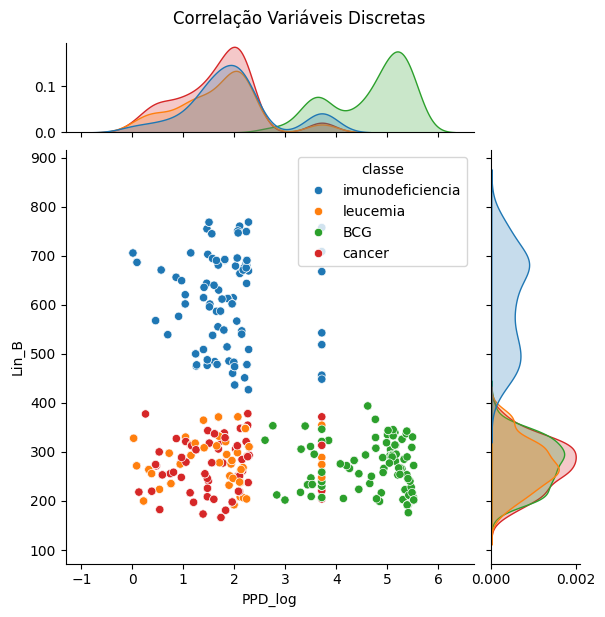

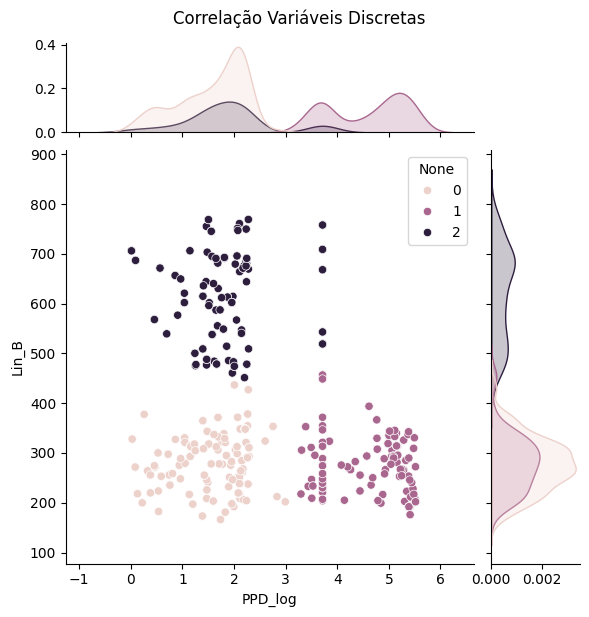

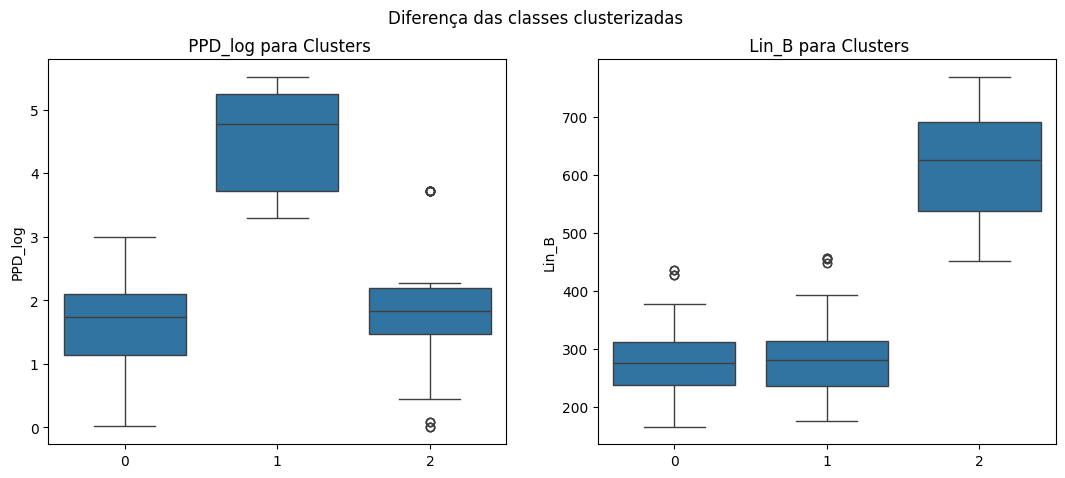

In [129]:
#LinT e PPD_log   IDENTIFICA 2 GRUPOS - RETIRAR  
i = bivariadas[1][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.7053

Silhouette Score -> 0.705
Calinski Harabasz Score -> 2195.319
Davies Bouldin Score -> 0.428
Adjusted Rand Score -> 0.322
Adjusted Mutual Info Score -> 0.568


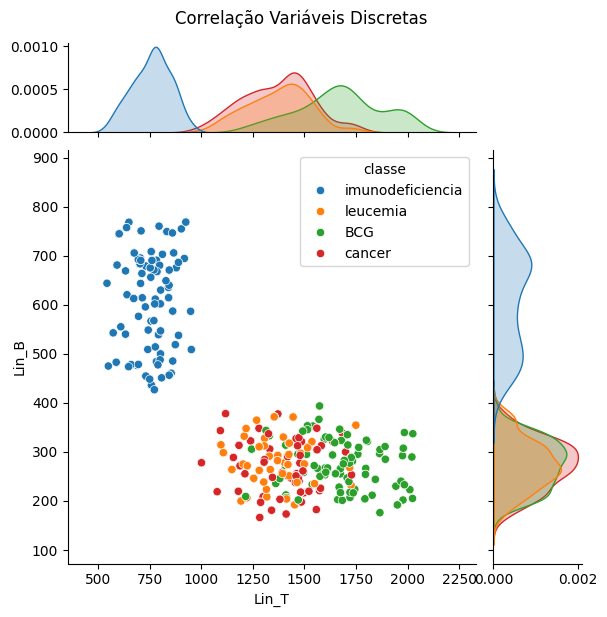

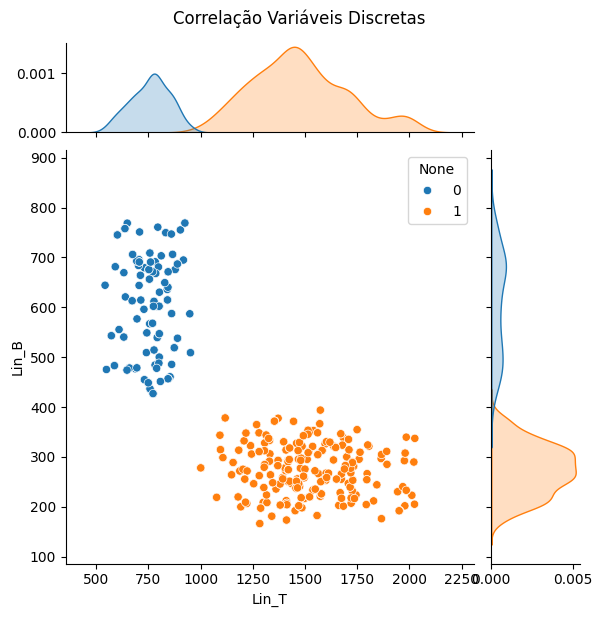

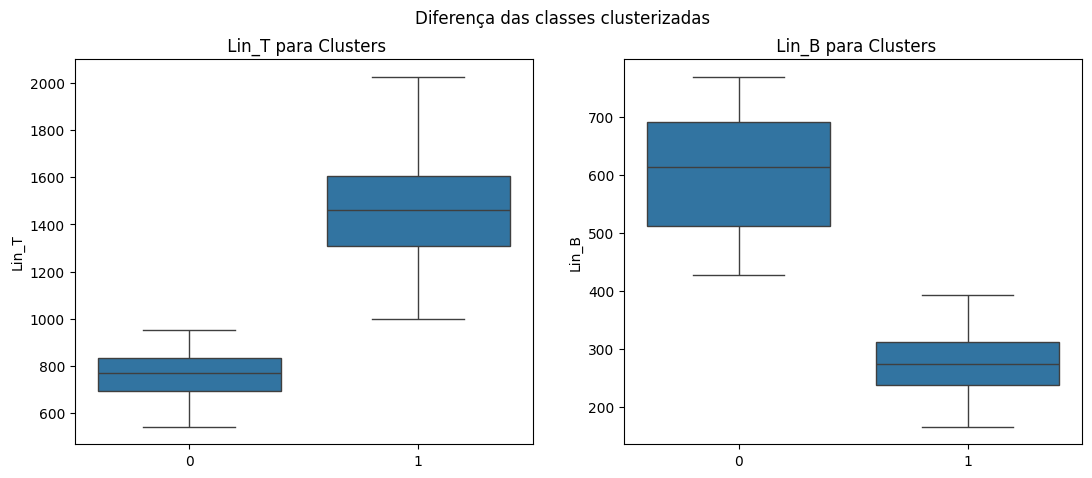

In [130]:
#LinT e LinB   IDENTIFICA 2 GRUPOS - RETIRAR  
i = bivariadas[1][1]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [131]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis

data = {}
for i in df_train.columns[:-1]:
    for j in df_train.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }   
)
df_metricas



,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
CD34_log_Lin_B,0.554,846.333,0.784,0.306,0.490
CD34_log_Lin_T,0.565,1024.610,0.633,0.670,0.788
CD34_log_PPD_log,0.536,937.362,0.768,0.329,0.449
Lin_B_CD34_log,0.554,846.333,0.784,0.306,0.490
Lin_B_Lin_T,0.705,2195.319,0.428,0.322,0.568
Lin_B_PPD_log,0.602,1376.660,0.549,0.609,0.680
Lin_T_CD34_log,0.565,1024.610,0.633,0.670,0.788
Lin_T_Lin_B,0.705,2195.319,0.428,0.322,0.568
Lin_T_PPD_log,0.553,1249.917,0.619,0.611,0.671
PPD_log_CD34_log,0.536,937.362,0.768,0.329,0.449


In [132]:
# Avaliação de clusterização - o que considerar

'''harabasz - extrinseco. ajuda a identificar o numero ideal de clusters (k) em casos nao supervisionados
        verifica a densidade e distancia entre clusters (foco extrinsico)
        quanto maior esse valor, mais bem separados os clusters

    davies bouldin - extrinseco. avalia separacao de clusters e a compactacao.
        verifica a distancia entre amostras de um cluster, e alem disso, calcula a distancia do centroide do cluster 
        em comparacao com as amostras do outro grupo.
        Quanto maior, maior separacao de clusteres+compactacao de grupo

    silhouette - intrinsico. mede a semelhanca de um ponto de dados a seu proprio cluster e com outros clusters.
        Mede mais a uniformidade do cluster do que a distancia entre clusters. Se mais disperso o cluster,
        menor a silhouete.
        prox de +1 - excelente ajuste. amostras muito uniformes e grupos distantes
        prox de -1 - a amostras deve ter sido classificada errada, pois esta mais proxima de outros clusters
        do que do que esta classificados
        prox de 0 - a amostra esta entre medidas de clusters. nao ha clusters bem difinidos

    ari (adjusted rand index) - extrinseco. para analise supervisionada
        avalia com base em um cluster conhecido. calcula a aplicacao correta das amostras por cluster rotulado
        1 = agrupamento perfeito
        0 - agrupamento sem sentido
        -1 - 
        para cada ponto, ele calcula a distancia da amostra para o cluster que ele deveria estar (diferente dos 
        outros ele nao faz calculo entre amostras)

    ami (adjusted mutual information) - extrinseco. tambem supervisionados
        nao calcula entre cluster, so observa o erro dentro de cada grupo.        
         1 = agrupamento perfeito
        0 - agrupamento sem sentido'''

'harabasz - extrinseco. ajuda a identificar o numero ideal de clusters (k) em casos nao supervisionados\n        verifica a densidade e distancia entre clusters (foco extrinsico)\n        quanto maior esse valor, mais bem separados os clusters\n\n    davies bouldin - extrinseco. avalia separacao de clusters e a compactacao.\n        verifica a distancia entre amostras de um cluster, e alem disso, calcula a distancia do centroide do cluster \n        em comparacao com as amostras do outro grupo.\n        Quanto maior, maior separacao de clusteres+compactacao de grupo\n\n    silhouette - intrinsico. mede a semelhanca de um ponto de dados a seu proprio cluster e com outros clusters.\n        Mede mais a uniformidade do cluster do que a distancia entre clusters. Se mais disperso o cluster,\n        menor a silhouete.\n        prox de +1 - excelente ajuste. amostras muito uniformes e grupos distantes\n        prox de -1 - a amostras deve ter sido classificada errada, pois esta mais proxima 

In [133]:
# Selecionando as melhores combinações de variáveis com base nas métricas
# de avaliação de clustering
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nlargest(1))
display(df_metricas["Davies Bouldin"].nlowest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

Lin_B_Lin_T    0.705
Name: Silhouette, dtype: float64

Lin_B_Lin_T    2195.319
Name: Calinski Harabasz, dtype: float64

AttributeError: 'Series' object has no attribute 'nlowest'

Utilizaremos as variáveis associadas a melhores métricas -> Lin_B, Lin_T e CD34_log

In [ ]:
col_selecionadas_train = df_train[[   #10,11
    "CD34_log", "Lin_B", "Lin_T",'classe']] #00,11 

Aplicamos agora a analise de cluster em repetido para avaliar a estabilidade das métricas para cada par de variáveis de interesse. Caso algum apresente muita variação, o par será retirado da análise.

In [ ]:
#Aplicando o processo em for aninhado para automatizar as combinações
#salva df de todas as combinações para avaliacao em separado

data = {}
for i in col_selecionadas_train.columns[:-1]:
    for j in col_selecionadas_train.columns[:-1]:
        if i != j:
            for a in range(100):
                cluster = Clustering(c1=i, c2=j, df=col_selecionadas_train, modelo=nome_modelo)
                _, metricas = cluster.cross_validation(print_metricas=False)
                data[a] = metricas

            df_metricas_repeti = pd.DataFrame(data).T.rename(
                columns={
                    0: "Silhouette",
                    1: "Calinski Harabasz",
                    2: "Davies Bouldin",
                    3: "Adjusted Rand",
                    4: "Adjusted Mutual Info",
                }
            )
            df_metricas_repeti = dump(df_metricas_repeti, f'./df_metricas{i}_{j}')

In [ ]:
#Exibindo metricas de uma combinação de variáveis numéicas para comparação
'''CD34_log e LinB'''

metricas_repeti_num = load('./df_metricasCD34_log_Lin_B')
metricas_num = metricas_repeti_num.describe()
metricas_num

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02
mean,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01
std,2.231632e-16,1.142596e-13,2.231632e-16,5.579081e-17,2.231632e-16
min,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01
25%,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01
50%,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01
75%,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01
max,5.540000e-01,8.463330e+02,7.840000e-01,3.060000e-01,4.900000e-01


In [ ]:
from IPython.display import display, Markdown


In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|{metricas_num['Silhouette'][1]}|   
|Silhouette_sd|{metricas_num['Silhouette'][2]}|   
|Calinski Harabasz_mean|{metricas_num['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{metricas_num['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{metricas_num['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{metricas_num['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{metricas_num['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{metricas_num['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{metricas_num['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{metricas_num['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\3718348264.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_mean|{metricas_num['Silhouette'][1]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\3718348264.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_sd|{metricas_num['Silhouette'][2]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\3718348264.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]


|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|0.5540000000000003|   
|Silhouette_sd|2.2316322462394835e-16|   
|Calinski Harabasz_mean|846.3329999999999|
|Calinski Harabasz_sd|1.1425957100746156e-13|
|Davies Bouldin_mean|0.7840000000000003|
|Davies Bouldin_sd|2.2316322462394835e-16|
|Adjusted Rand_mean|0.30600000000000005|
|Adjusted Rand_sd|5.579080615598709e-17|
|Adjusted Mutual Info_mean|0.4900000000000002|
|Adjusted Mutual Info_sd|2.2316322462394835e-16|



### Validação

In [ ]:
# Importando os dados de validação
df_valid = pd.concat(
    [
        load("./df_trabalho_X_valid"),
        load("./df_trabalho_y_valid"),
    ],
    axis=1,
)
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
904,-4.354233,683.860757,702.521323,2.228345,True,False,False,True,False,True,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,False,True,True,False,False,True,leucemia
139,-2.771307,223.769444,1315.554814,0.532531,False,True,True,False,False,True,cancer
526,-1.810700,364.827049,1268.215382,1.394407,False,True,True,False,False,True,cancer
868,-2.473679,271.804503,1187.576700,0.468055,False,True,True,False,False,True,cancer


> Análise gráfica das variáveis numericas

In [ ]:
col_selecionadas_train

,CD34_log,Lin_B,Lin_T,classe
541,-6.605859,587.422573,861.125119,imunodeficiencia
440,-4.329437,500.185650,801.998581,imunodeficiencia
482,-1.748794,208.645029,1299.553614,leucemia
422,-4.197952,537.954188,889.391214,imunodeficiencia
778,-1.880539,274.394770,1419.982269,leucemia
...,...,...,...,...
106,-2.396662,313.523182,1182.565006,cancer
270,-8.578393,275.768311,1688.669407,BCG
860,-4.369494,307.701697,1979.374657,BCG
435,-4.601040,342.577025,1492.105460,BCG


Avaliacao das métricas de cluster para as combinações possíveis de variáveis que ja haviam sido definidas como mais importantes no treino

In [ ]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis

data = {}
df_selecionadas_valid = df_valid[["Lin_T",  
    "CD34_log", "Lin_B", 'classe']]
for i in df_selecionadas_valid.columns[:-1]:
    for j in df_selecionadas_valid.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_selecionadas_valid, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas_valid = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }   
)
df_metricas_valid


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
Lin_T_CD34_log,0.576,309.235,0.639,0.677,0.799
Lin_T_Lin_B,0.736,775.708,0.370,0.303,0.553
CD34_log_Lin_T,0.576,309.235,0.639,0.677,0.799
CD34_log_Lin_B,0.555,326.401,0.663,0.687,0.802
Lin_B_Lin_T,0.736,775.708,0.370,0.303,0.553
Lin_B_CD34_log,0.555,326.401,0.663,0.687,0.802


In [ ]:
sil_valid = df_metricas_valid["Silhouette"].nlargest(1)
ca_valid =df_metricas_valid["Calinski Harabasz"].nlargest(1)
db_valid = df_metricas_valid["Davies Bouldin"].nlargest(1)
ari_valid = df_metricas_valid["Adjusted Rand"].nlargest(1)
ami_valid = df_metricas_valid["Adjusted Mutual Info"].nlargest(1)


sil_train = df_metricas["Silhouette"].nlargest(1)
ca_train = df_metricas["Calinski Harabasz"].nlargest(1)
db_train = df_metricas["Davies Bouldin"].nlargest(1)
ari_train = df_metricas["Adjusted Rand"].nlargest(1)
ami_train = df_metricas["Adjusted Mutual Info"].nlargest(1)


In [ ]:
df_metricas_valid['Silhouette'].nlargest(1).index


Index(['Lin_T_Lin_B'], dtype='object')

In [ ]:
# Cmomparativo de metricas de avaliacao de treino e validacao
display(df_metricas_valid["Silhouette"].nlargest(1))
display(df_metricas_valid["Calinski Harabasz"].nlargest(1))
display(df_metricas_valid["Davies Bouldin"].nlargest(1))
display(df_metricas_valid["Adjusted Rand"].nlargest(1))
display(df_metricas_valid["Adjusted Mutual Info"].nlargest(1))

Lin_T_Lin_B    0.736
Name: Silhouette, dtype: float64

Lin_T_Lin_B    775.708
Name: Calinski Harabasz, dtype: float64

CD34_log_Lin_B    0.663
Name: Davies Bouldin, dtype: float64

CD34_log_Lin_B    0.687
Name: Adjusted Rand, dtype: float64

CD34_log_Lin_B    0.802
Name: Adjusted Mutual Info, dtype: float64

In [ ]:
teste = f'''

|Métrica|Métricas Treino Variáveis| Valor |Métricas Validação Variáveis| Valor
|-|-|-|-|-|     
|Silhouette|{sil_train.index}|{sil_train[0]}|{sil_valid.index}|{sil_valid[0]}|
|Calinski Harabasz|{ca_train.index}|{ca_train[0]}|{ca_valid.index}|{ca_valid[0]}|
|Davies Bouldin|{db_train.index}|{db_train[0]}|{db_valid.index}|{db_valid[0]}|
|Adjusted Rand|{ari_train.index}|{ari_train[0]}|{ari_valid.index}|{ari_valid[0]}|
|Adjusted Mutual Info|{ami_train.index}|{ami_train[0]}|{ami_valid.index}|{ami_valid[0]}|



'''

display(Markdown(teste))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2084336381.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette|{sil_train.index}|{sil_train[0]}|{sil_valid.index}|{sil_valid[0]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2084336381.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Calinski Harabasz|{ca_train.index}|{ca_train[0]}|{ca_valid.index}|{ca_valid[0]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2084336381.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFra



|Métrica|Métricas Treino Variáveis| Valor |Métricas Validação Variáveis| Valor
|-|-|-|-|-|     
|Silhouette|Index(['Lin_B_Lin_T'], dtype='object')|0.705|Index(['Lin_T_Lin_B'], dtype='object')|0.736|
|Calinski Harabasz|Index(['Lin_B_Lin_T'], dtype='object')|2195.319|Index(['Lin_T_Lin_B'], dtype='object')|775.708|
|Davies Bouldin|Index(['CD34_log_Lin_B'], dtype='object')|0.784|Index(['CD34_log_Lin_B'], dtype='object')|0.663|
|Adjusted Rand|Index(['CD34_log_Lin_T'], dtype='object')|0.67|Index(['CD34_log_Lin_B'], dtype='object')|0.687|
|Adjusted Mutual Info|Index(['CD34_log_Lin_T'], dtype='object')|0.788|Index(['CD34_log_Lin_B'], dtype='object')|0.802|





Aplicamos agora a analise de cluster em repetido para avaliar a estabilidade das métricas para os pares de variáveis selecionadas no treinamento 

In [ ]:
'''CD34_log e Lin B '''
# Repetindo as análises de clustering para a combinação de variáveis
# CD34_log e Lin B, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="CD34_log", c2="Lin_B", df=df_valid, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.555,326.401,0.663,0.687,0.802
1,0.555,326.401,0.663,0.687,0.802
2,0.555,326.401,0.663,0.687,0.802
3,0.555,326.401,0.663,0.687,0.802
4,0.555,326.401,0.663,0.687,0.802


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis de CD43_log e Lin B, repetidas 100 vezes
metricas_valid_kmeans = df_metricas_repeti_valid.describe()
metricas_valid_kmeans

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,1.000000e+02,100.000,1.000000e+02,100.000,100.000
mean,5.550000e-01,326.401,6.630000e-01,0.687,0.802
std,1.115816e-16,0.000,1.115816e-16,0.000,0.000
min,5.550000e-01,326.401,6.630000e-01,0.687,0.802
25%,5.550000e-01,326.401,6.630000e-01,0.687,0.802
50%,5.550000e-01,326.401,6.630000e-01,0.687,0.802
75%,5.550000e-01,326.401,6.630000e-01,0.687,0.802
max,5.550000e-01,326.401,6.630000e-01,0.687,0.802


In [ ]:
dump(df_metricas_repeti_valid, './df_metricas_repeti_validCD34_log_LinB_kmeans')

['./df_metricas_repeti_validCD34_log_LinB_kmeans']

Tabela comparativa das métricas de avaliação para validaçao e teste

In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|{metricas_num['Silhouette'][1]}|{metricas_valid_kmeans['Silhouette'][1]}|   
|Silhouette_sd|{metricas_num['Silhouette'][2]}|{metricas_valid_kmeans['Silhouette'][2]}|   
|Calinski Harabasz_mean|{metricas_num['Calinski Harabasz'][1]}|{metricas_valid_kmeans['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{metricas_num['Calinski Harabasz'][2]}|{metricas_valid_kmeans['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{metricas_num['Davies Bouldin'][1]}|{metricas_valid_kmeans['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{metricas_num['Davies Bouldin'][2]}|{metricas_valid_kmeans['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{metricas_num['Adjusted Rand'][1]}|{metricas_valid_kmeans['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{metricas_num['Adjusted Rand'][2]}|{metricas_valid_kmeans['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{metricas_num['Adjusted Mutual Info'][1]}|{metricas_valid_kmeans['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{metricas_num['Adjusted Mutual Info'][2]}|{metricas_valid_kmeans['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1904375319.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_mean|{metricas_num['Silhouette'][1]}|{metricas_valid_kmeans['Silhouette'][1]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1904375319.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_sd|{metricas_num['Silhouette'][2]}|{metricas_valid_kmeans['Silhouette'][2]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1904375319.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons


|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|0.5540000000000003|0.5549999999999999|   
|Silhouette_sd|2.2316322462394835e-16|1.1158161231197418e-16|   
|Calinski Harabasz_mean|846.3329999999999|326.401|
|Calinski Harabasz_sd|1.1425957100746156e-13|0.0|
|Davies Bouldin_mean|0.7840000000000003|0.6630000000000001|
|Davies Bouldin_sd|2.2316322462394835e-16|1.1158161231197418e-16|
|Adjusted Rand_mean|0.30600000000000005|0.687|
|Adjusted Rand_sd|5.579080615598709e-17|0.0|
|Adjusted Mutual Info_mean|0.4900000000000002|0.802|
|Adjusted Mutual Info_sd|2.2316322462394835e-16|0.0|



=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5783

Silhouette Score -> 0.555
Calinski Harabasz Score -> 326.401
Davies Bouldin Score -> 0.663
Adjusted Rand Score -> 0.687
Adjusted Mutual Info Score -> 0.802


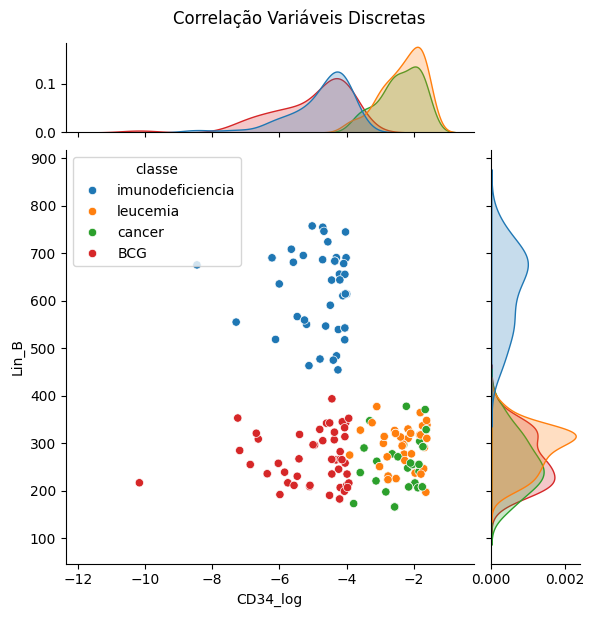

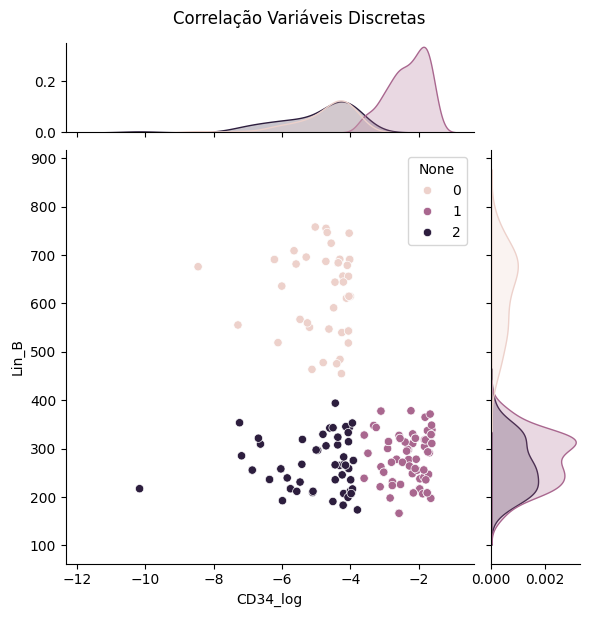

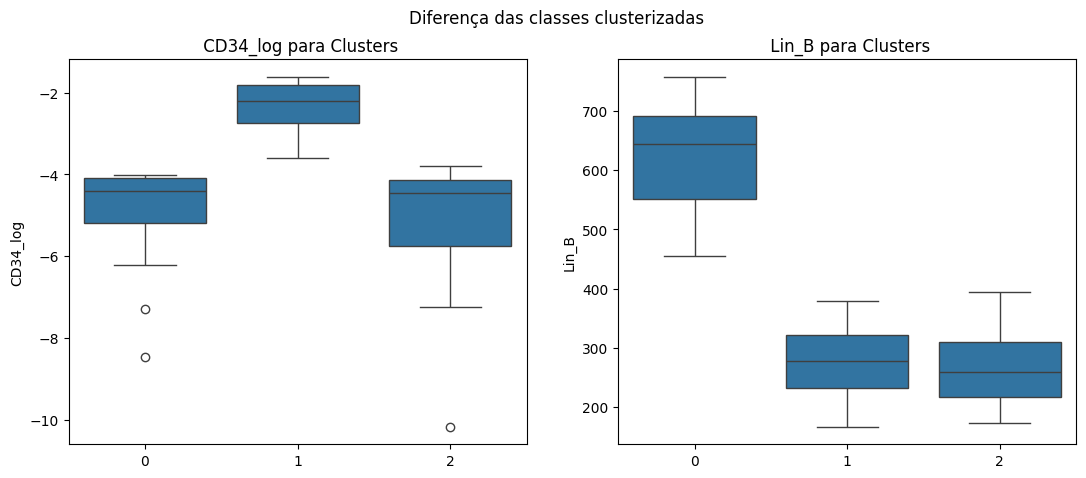

In [ ]:
# Analisando os clusters para variável CD34_log e Lin B

cluster = Clustering(
    c1='CD34_log', c2='Lin_B', df=df_selecionadas_valid, modelo=nome_modelo
)
cluster.cross_validation()


=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5958

Silhouette Score -> 0.576
Calinski Harabasz Score -> 309.235
Davies Bouldin Score -> 0.639
Adjusted Rand Score -> 0.677
Adjusted Mutual Info Score -> 0.799


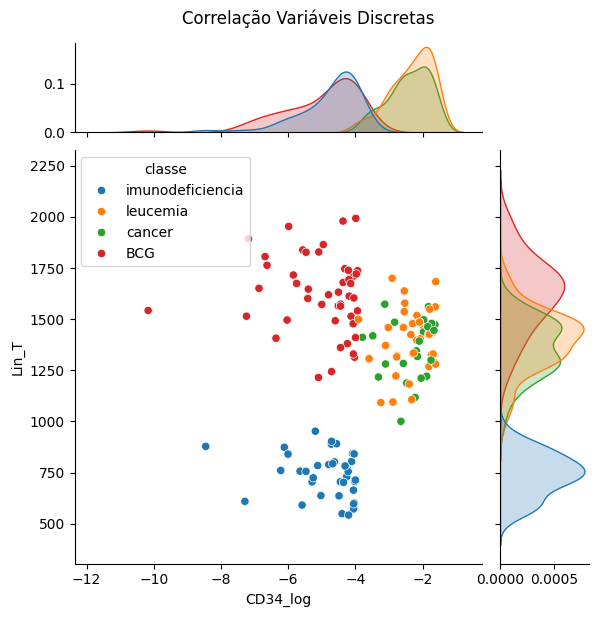

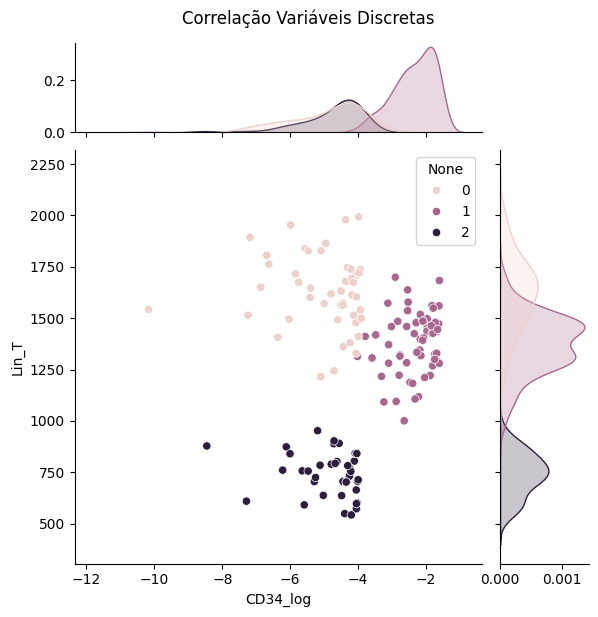

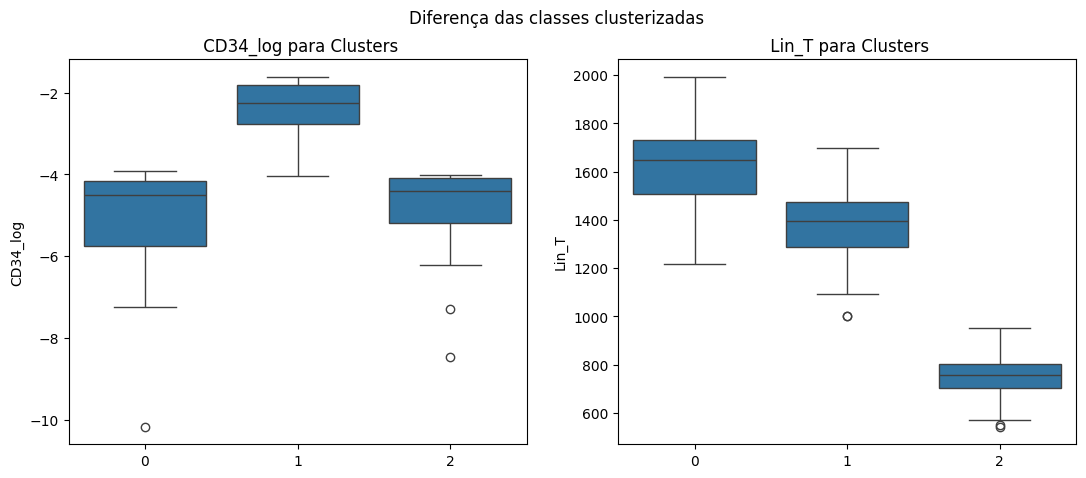

In [ ]:
# Analisando os clusters para variável CD34_log e Lin T

cluster = Clustering(
    c1='CD34_log', c2='Lin_T', df=df_selecionadas_valid, modelo=nome_modelo
)
cluster.cross_validation()

## DBSCAN

### Treino

In [ ]:
# Importando os dados de treino
df_train = pd.concat(
    [
        load("./df_trabalho_X_train"),
        load("./df_trabalho_y_train"),
    ],
    axis=1,
)
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
541,-6.605859,587.422573,861.125119,1.728509,True,False,False,True,False,True,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,True,False,False,True,False,True,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,False,True,True,False,False,True,leucemia
422,-4.197952,537.954188,889.391214,1.574182,True,False,False,True,False,True,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,False,True,True,False,False,True,leucemia


Avaliando os pares de variáveis numéricas pela análise gráfica

In [ ]:
df_train = df_train[['CD34_log', 'Lin_B', 'Lin_T', 'PPD_log','classe']]

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5366

Silhouette Score -> 0.536
Calinski Harabasz Score -> 937.362
Davies Bouldin Score -> 0.768
Adjusted Rand Score -> 0.329
Adjusted Mutual Info Score -> 0.449


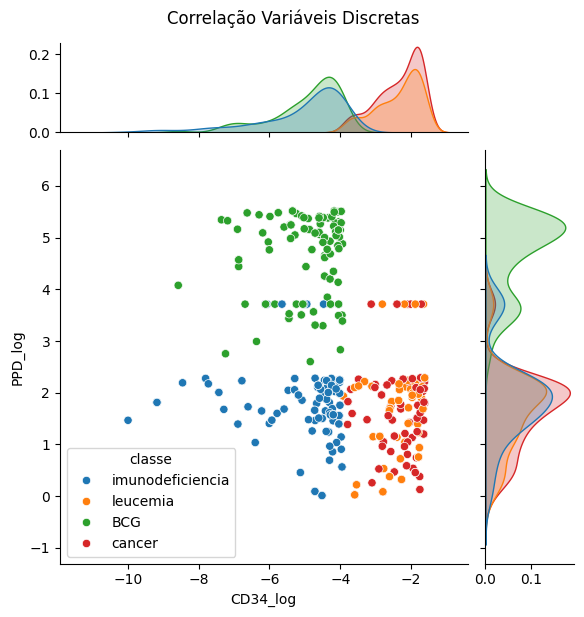

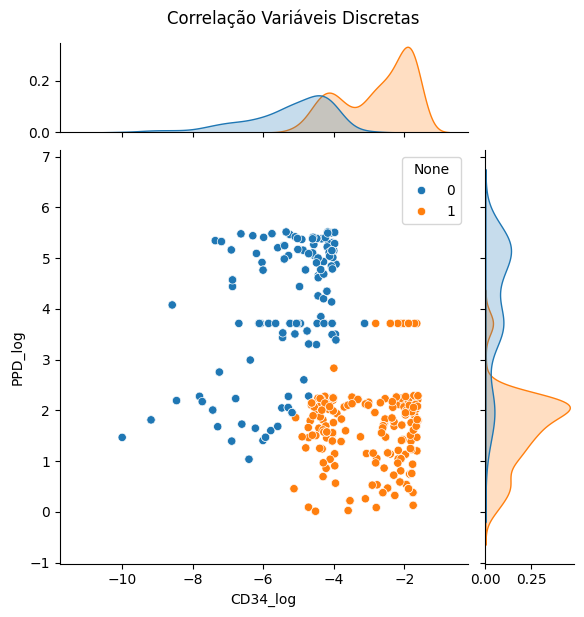

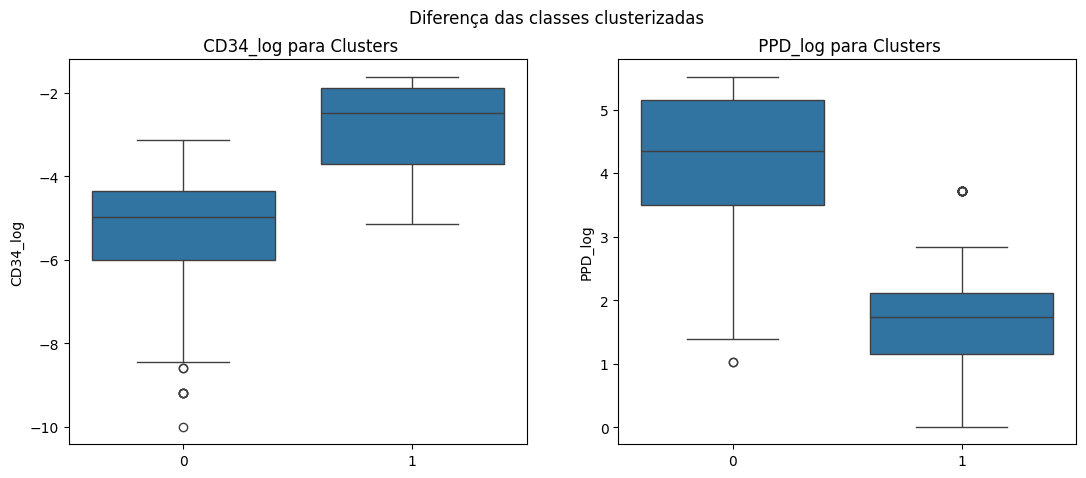

In [ ]:
# Definindo um objeto de clustering com os dados de treino
nome_modelo = "kmeans"
bivariadas = [
    ["CD34_log", "Lin_B"],
    ["PPD_log", "Lin_T"],
]

#analise par CD34_log e PPD_log - forma 2 grupos ruins
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[1][0], df=df_train, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5654

Silhouette Score -> 0.565
Calinski Harabasz Score -> 1024.61
Davies Bouldin Score -> 0.633
Adjusted Rand Score -> 0.67
Adjusted Mutual Info Score -> 0.788


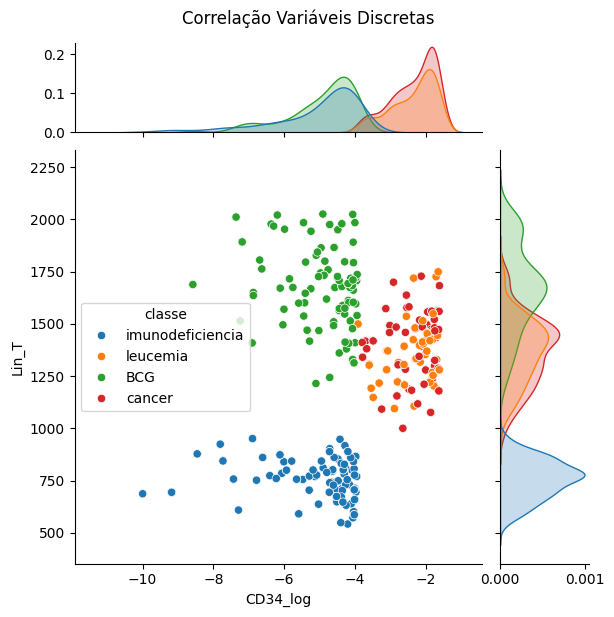

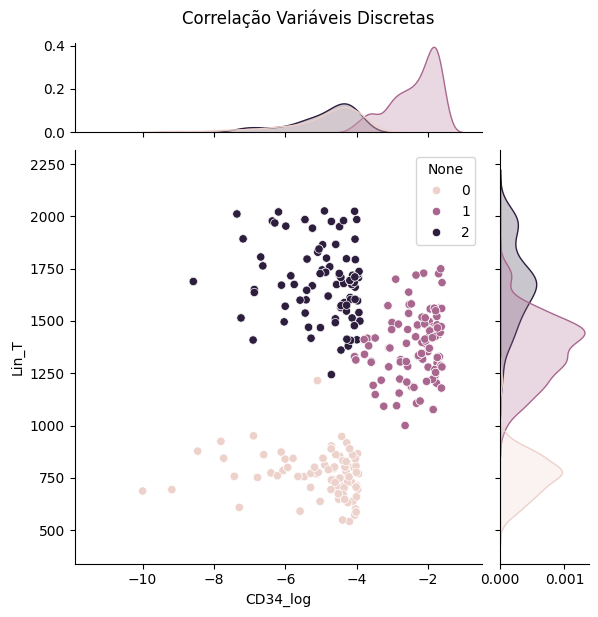

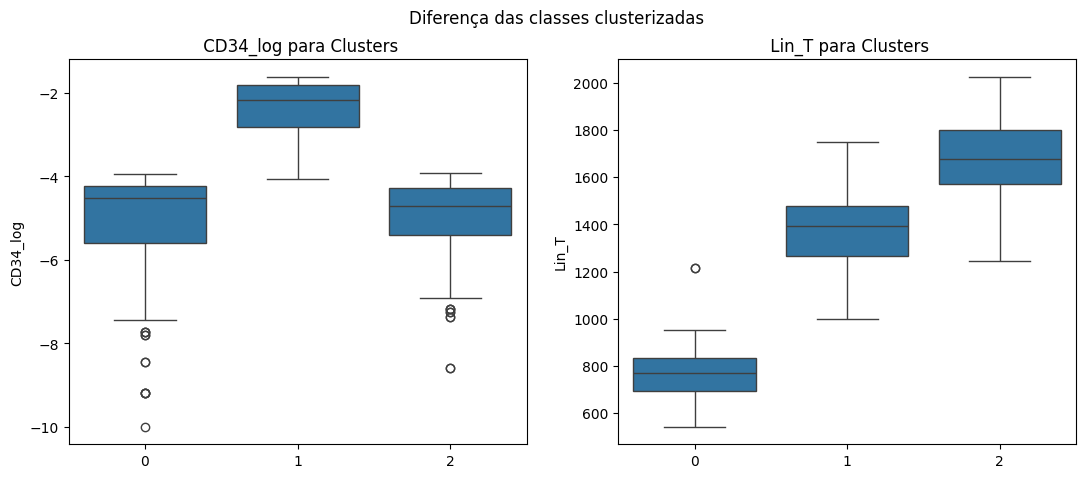

In [ ]:
#analise par CD34_log e Lin_T - 3 grupos
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[1][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5624

Silhouette Score -> 0.554
Calinski Harabasz Score -> 846.333
Davies Bouldin Score -> 0.784
Adjusted Rand Score -> 0.306
Adjusted Mutual Info Score -> 0.49


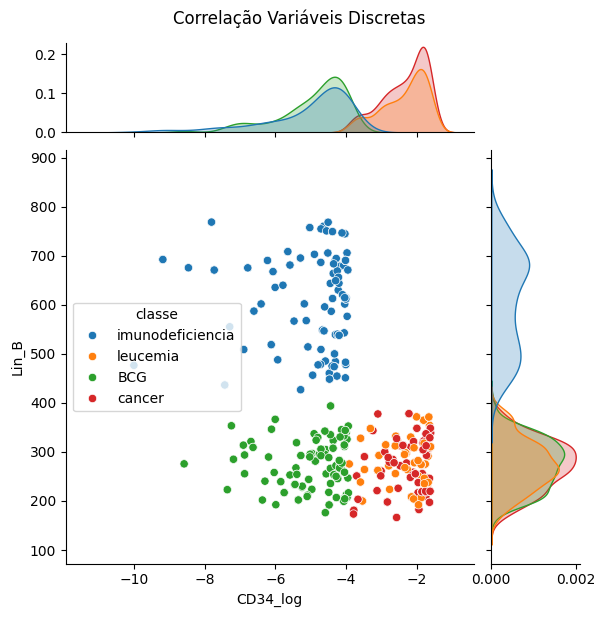

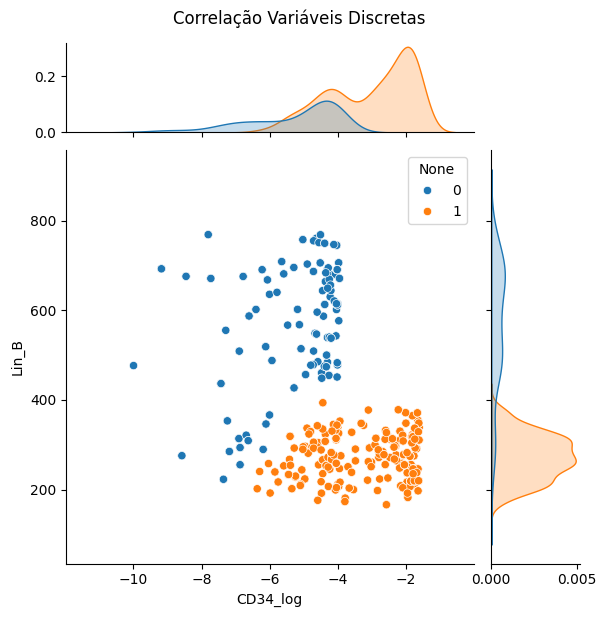

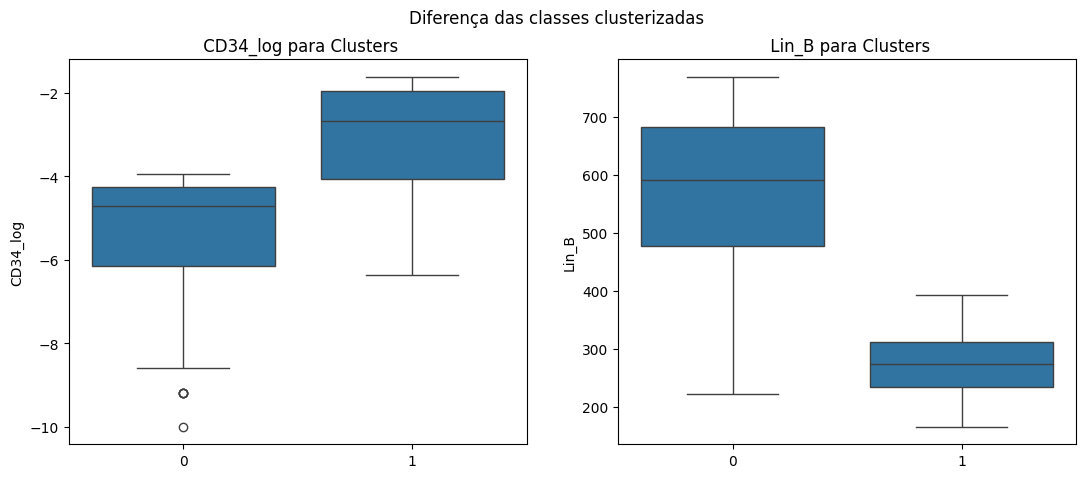

In [ ]:
#analise par Lin B e CD34_log - 2 grupos
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.7053

Silhouette Score -> 0.705
Calinski Harabasz Score -> 2195.319
Davies Bouldin Score -> 0.428
Adjusted Rand Score -> 0.322
Adjusted Mutual Info Score -> 0.568


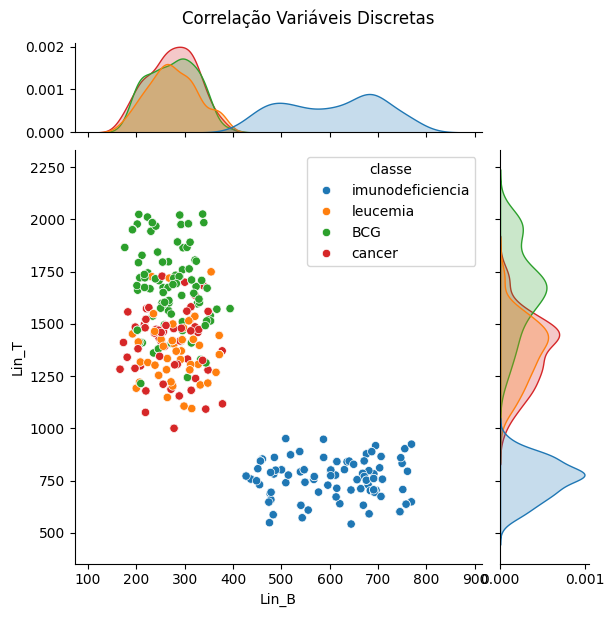

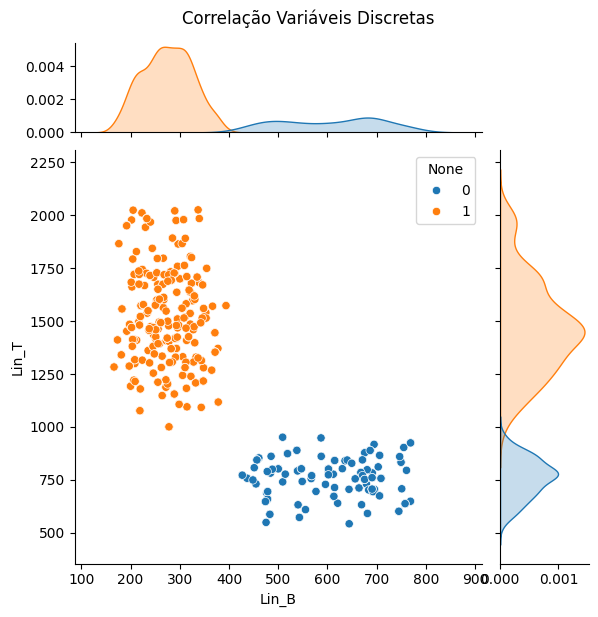

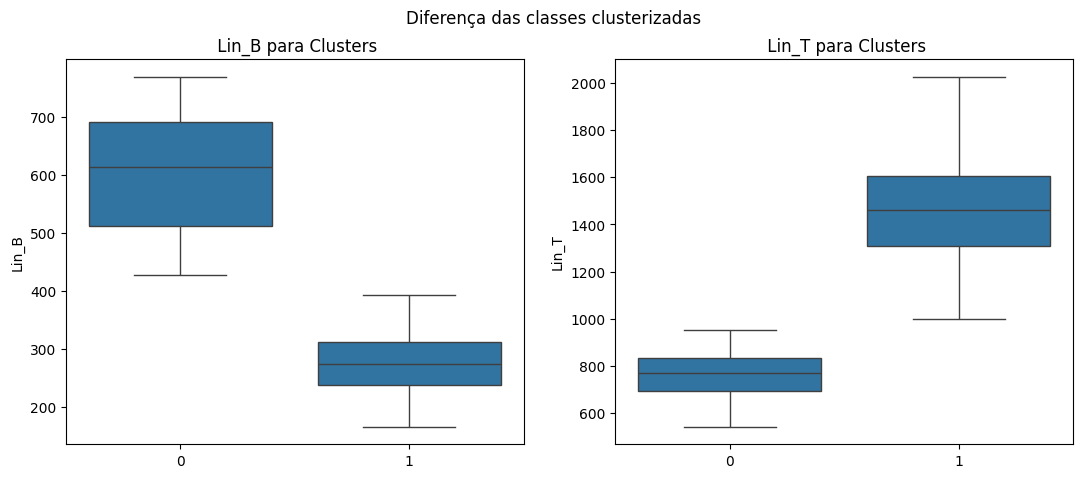

In [ ]:
#analise par Lin B e Lin_T - 2 grupos
cluster = Clustering(
    c1=bivariadas[0][1], c2=bivariadas[1][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.6028

Silhouette Score -> 0.602
Calinski Harabasz Score -> 1376.66
Davies Bouldin Score -> 0.549
Adjusted Rand Score -> 0.609
Adjusted Mutual Info Score -> 0.68


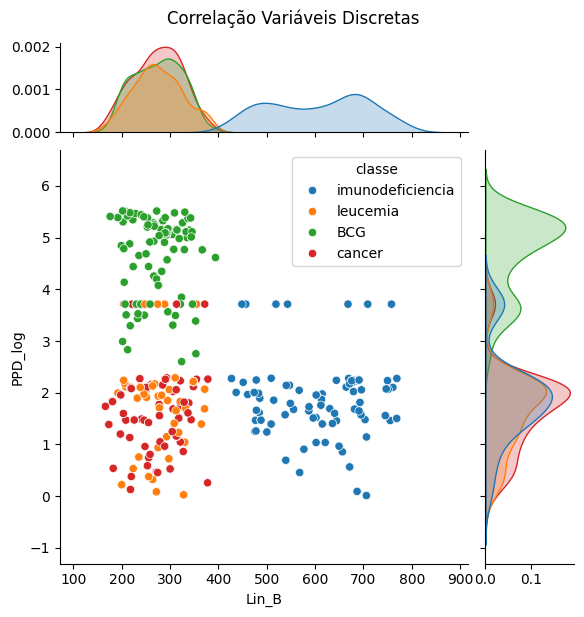

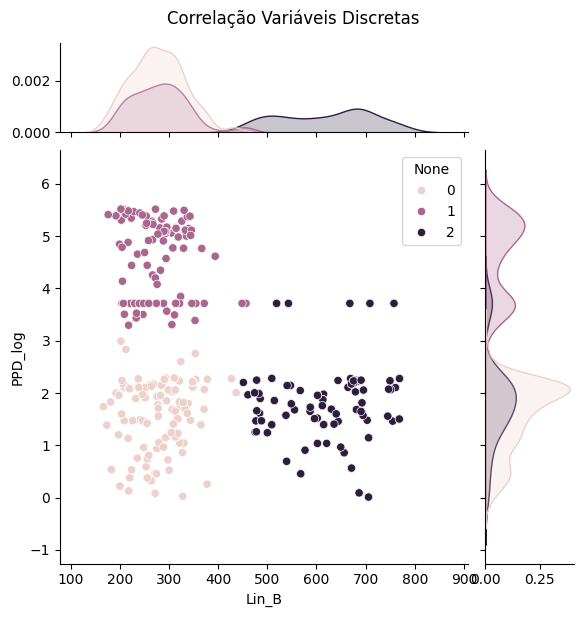

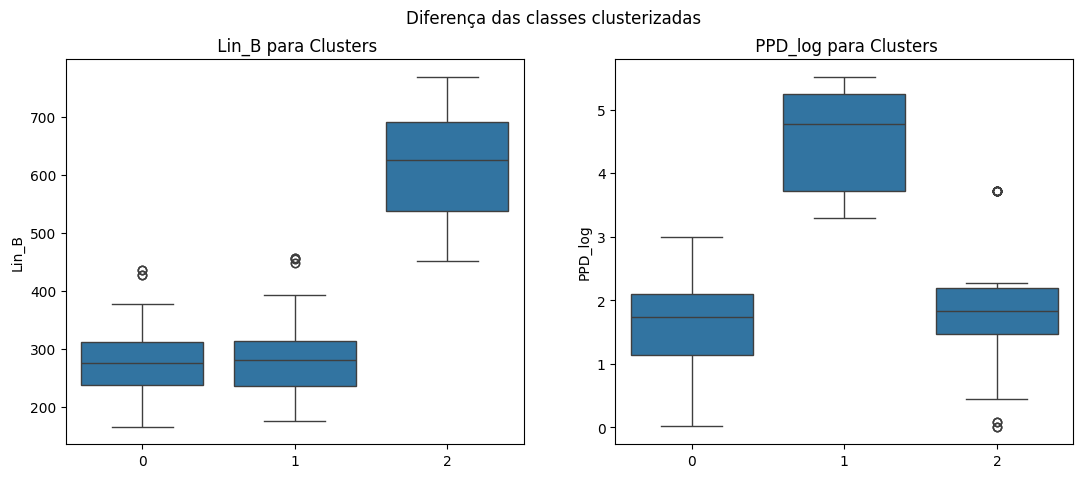

In [ ]:
#analise par LinB e PPD_log - 3 grupos
cluster = Clustering(
    c1=bivariadas[0][1], c2=bivariadas[1][0], df=df_train, modelo=nome_modelo
)
cluster.cross_validation()

In [ ]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis
data = {}
for i in df_train.columns[:-1]:
    for j in df_train.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas_dbscan = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_dbscan.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
CD34_log_Lin_B,0.554,846.333,0.784,0.306,0.490
CD34_log_Lin_T,0.565,1024.610,0.633,0.670,0.788
CD34_log_PPD_log,0.536,937.362,0.768,0.329,0.449
Lin_B_CD34_log,0.554,846.333,0.784,0.306,0.490
Lin_B_Lin_T,0.705,2195.319,0.428,0.322,0.568


In [ ]:
# Selecionando as melhores combinações de variáveis com base nas métricas de
# avaliação de clustering
display(df_metricas_dbscan["Silhouette"].nlargest(1))
display(df_metricas_dbscan["Calinski Harabasz"].nsmallest(1))
display(df_metricas_dbscan["Davies Bouldin"].nlargest(1))
display(df_metricas_dbscan["Adjusted Rand"].nlargest(1))
display(df_metricas_dbscan["Adjusted Mutual Info"].nlargest(1))

Lin_B_Lin_T    0.705
Name: Silhouette, dtype: float64

CD34_log_Lin_B    846.333
Name: Calinski Harabasz, dtype: float64

CD34_log_Lin_B    0.784
Name: Davies Bouldin, dtype: float64

CD34_log_Lin_T    0.67
Name: Adjusted Rand, dtype: float64

CD34_log_Lin_T    0.788
Name: Adjusted Mutual Info, dtype: float64

Seguiremos a análise com as variáveis de melhores métricas -> Lin B, Lin T e CD34_log

In [ ]:
col_selecionadas_train = df_train[[   #10,11
    "CD34_log", "Lin_B", "Lin_T",'classe']] #00,11 

Analisamos os pares das variáveis selecionadas para a estabilidade em um cross validation de 100x. Aqui analisarei o mesmo par de Kmeans para comparação - CD43_log e Lin B

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
#  100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="CD34_log", c2="Lin_B", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.554,846.333,0.784,0.306,0.49
1,0.554,846.333,0.784,0.306,0.49
2,0.554,846.333,0.784,0.306,0.49
3,0.554,846.333,0.784,0.306,0.49
4,0.554,846.333,0.784,0.306,0.49


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis CD34_log e Lin B, repetidas 100 vezes
metricas_train_dbscan = df_metricas_repeti.describe()

In [ ]:
dump(df_metricas_repeti, 'df_metricas_repeti_treino_CD43_log_Lin_B_dbscan')

['df_metricas_repeti_treino_CD43_log_Lin_B_dbscan']

In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|{df_metricas_repeti['Silhouette'][1]}|   
|Silhouette_sd|{df_metricas_repeti['Silhouette'][2]}|   
|Calinski Harabasz_mean|{df_metricas_repeti['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{df_metricas_repeti['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{df_metricas_repeti['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{df_metricas_repeti['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{df_metricas_repeti['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{df_metricas_repeti['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{df_metricas_repeti['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{df_metricas_repeti['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))


|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|0.554|   
|Silhouette_sd|0.554|   
|Calinski Harabasz_mean|846.333|
|Calinski Harabasz_sd|846.333|
|Davies Bouldin_mean|0.784|
|Davies Bouldin_sd|0.784|
|Adjusted Rand_mean|0.306|
|Adjusted Rand_sd|0.306|
|Adjusted Mutual Info_mean|0.49|
|Adjusted Mutual Info_sd|0.49|



### Validação

In [ ]:
# Importando os dados de validação
df_valid = pd.concat(
    [
        load("./df_trabalho_X_valid"),
        load("./df_trabalho_y_valid"),
    ],
    axis=1,
)
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
904,-4.354233,683.860757,702.521323,2.228345,True,False,False,True,False,True,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,False,True,True,False,False,True,leucemia
139,-2.771307,223.769444,1315.554814,0.532531,False,True,True,False,False,True,cancer
526,-1.810700,364.827049,1268.215382,1.394407,False,True,True,False,False,True,cancer
868,-2.473679,271.804503,1187.576700,0.468055,False,True,True,False,False,True,cancer


Separando as colunas selecionadas no treino

In [ ]:
df_valid = df_valid[['CD34_log','Lin_B','Lin_T','classe']]

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# Lin_B e CD34_log, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(
        c1='CD34_log', c2='Lin_B', df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_dbscan = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_dbscan.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.555,326.401,0.663,0.687,0.802
1,0.555,326.401,0.663,0.687,0.802
2,0.555,326.401,0.663,0.687,0.802
3,0.555,326.401,0.663,0.687,0.802
4,0.555,326.401,0.663,0.687,0.802


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis CD34_log e Lin_B, repetidas 100 vezes
metricas_valid_dbscan = df_metricas_repeti_valid_dbscan.describe()

In [ ]:
dump(df_metricas_repeti_valid_dbscan, './df_metricas_repeti_validCD34_log_LinB_dbscan')

['./df_metricas_repeti_validCD34_log_LinB_dbscan']

Tabela comparativa das métricas de avaliação para validaçao e teste

In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|{metricas_train_dbscan['Silhouette'][1]}|{metricas_valid_dbscan['Silhouette'][1]}|   
|Silhouette_sd|{metricas_train_dbscan['Silhouette'][2]}|{metricas_valid_dbscan['Silhouette'][2]}|   
|Calinski Harabasz_mean|{metricas_train_dbscan['Calinski Harabasz'][1]}|{metricas_valid_dbscan['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{metricas_train_dbscan['Calinski Harabasz'][2]}|{metricas_valid_dbscan['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{metricas_train_dbscan['Davies Bouldin'][1]}|{metricas_valid_dbscan['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{metricas_train_dbscan['Davies Bouldin'][2]}|{metricas_valid_dbscan['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{metricas_train_dbscan['Adjusted Rand'][1]}|{metricas_valid_dbscan['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{metricas_train_dbscan['Adjusted Rand'][2]}|{metricas_valid_dbscan['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{metricas_train_dbscan['Adjusted Mutual Info'][1]}|{metricas_valid_dbscan['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{metricas_train_dbscan['Adjusted Mutual Info'][2]}|{metricas_valid_dbscan['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2651831211.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_mean|{metricas_train_dbscan['Silhouette'][1]}|{metricas_valid_dbscan['Silhouette'][1]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2651831211.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_sd|{metricas_train_dbscan['Silhouette'][2]}|{metricas_valid_dbscan['Silhouette'][2]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\2651831211.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treat


|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|0.5540000000000003|0.5549999999999999|   
|Silhouette_sd|2.2316322462394835e-16|1.1158161231197418e-16|   
|Calinski Harabasz_mean|846.3329999999999|326.401|
|Calinski Harabasz_sd|1.1425957100746156e-13|0.0|
|Davies Bouldin_mean|0.7840000000000003|0.6630000000000001|
|Davies Bouldin_sd|2.2316322462394835e-16|1.1158161231197418e-16|
|Adjusted Rand_mean|0.30600000000000005|0.687|
|Adjusted Rand_sd|5.579080615598709e-17|0.0|
|Adjusted Mutual Info_mean|0.4900000000000002|0.802|
|Adjusted Mutual Info_sd|2.2316322462394835e-16|0.0|



=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5783

Silhouette Score -> 0.555
Calinski Harabasz Score -> 326.401
Davies Bouldin Score -> 0.663
Adjusted Rand Score -> 0.687
Adjusted Mutual Info Score -> 0.802


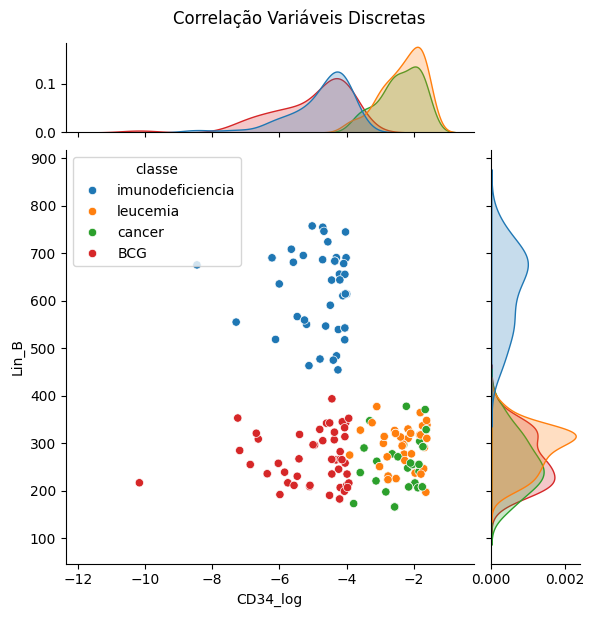

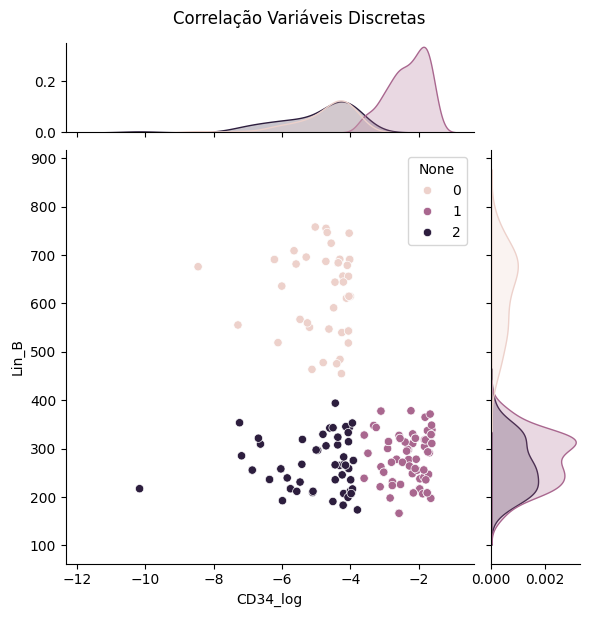

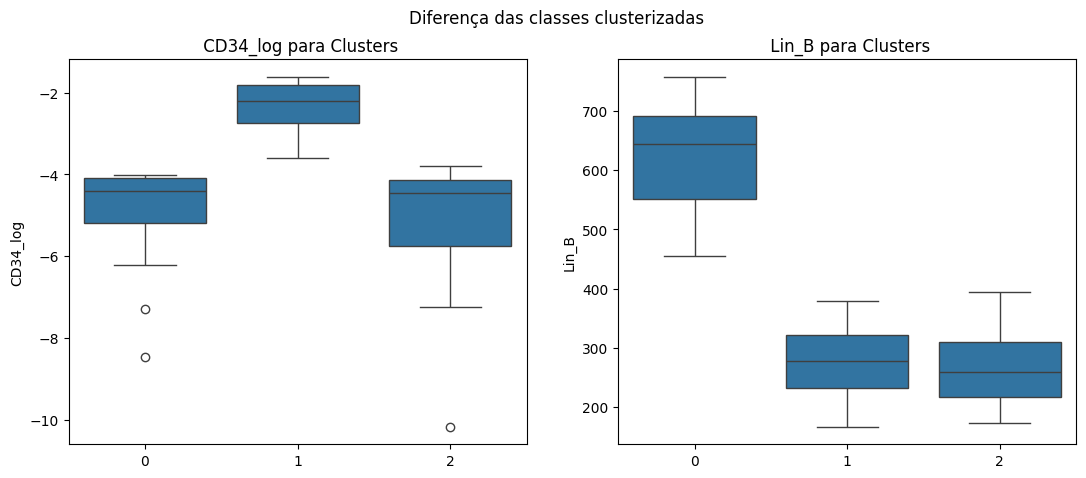

In [ ]:
# Analisando os clusters para variável CD34_log e Lin B

cluster = Clustering(
    c1='CD34_log', c2='Lin_B', df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

## Agrupamento Hierarquico

### Treino

In [ ]:
param_combinations = [
    {"n_clusters": k, "linkage": "ward", "metric": "euclidean"} for k in [2, 3, 4, 5, 6]
] + [
    {"n_clusters": k, "linkage": linkage, "metric": metric}
    for k in [2, 3, 4, 5, 6]
    for linkage in ["complete", "average", "single"]
    for metric in ["euclidean", "manhattan", "cosine"]
]
param_combinations

[{'n_clusters': 2, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 4, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 5, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 6, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'cosine'},
 {'n_clusters': 3, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'complete', 'metri

In [ ]:
# Definindo um objeto de clustering com os dados de treino
#retiramos as categoricas para a analise grafica (FOXP3_A e FOXP3_N, Igs_A e Igs_B, citoc_A e citoc_B)    
# ["FOXP3_Normal", "FOXP3_Alterado"],
#    ["Igs_Baixo", "Igs_Alto"],
#    ["citoc_Baixo", "citoc_Alto"]
nome_modelo = "agglomerative"

bivariadas = [
    ["CD34_log", "Lin_B"],
    ["PPD_log", "Lin_T"],
]


> Análise gráfica da variáveis numéricas

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.5596

Silhouette Score -> 0.548
Calinski Harabasz Score -> 739.271
Davies Bouldin Score -> 0.719
Adjusted Rand Score -> 0.306
Adjusted Mutual Info Score -> 0.535


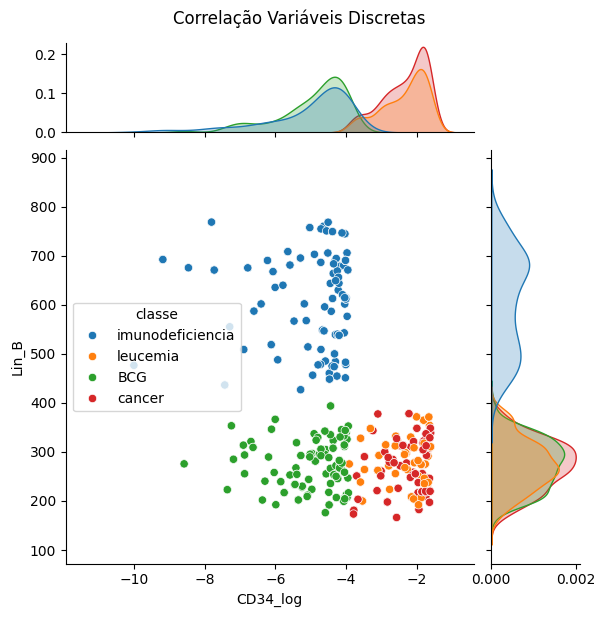

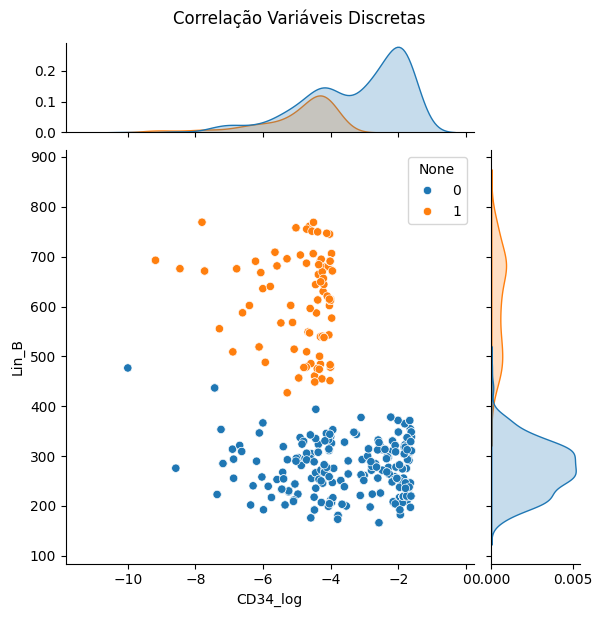

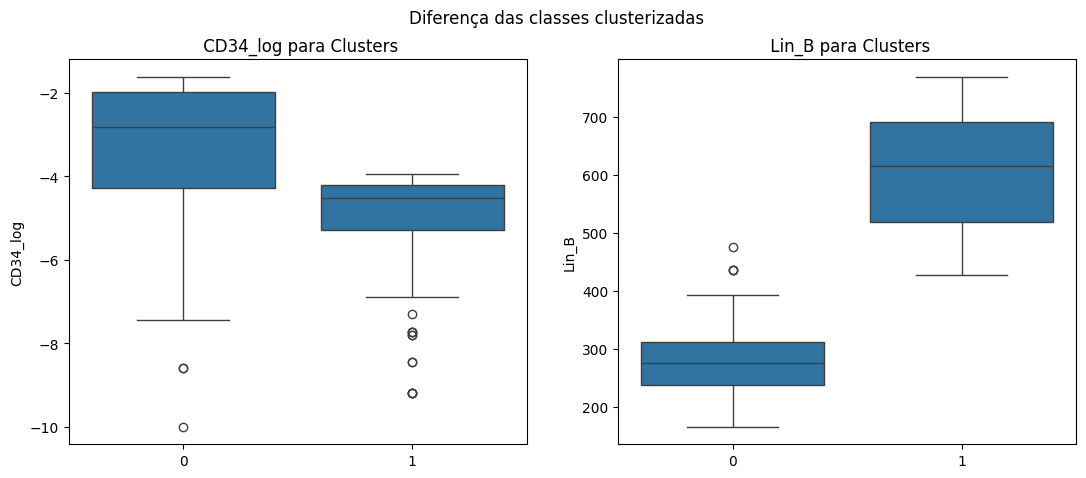

In [ ]:
#CD34_log e Lin_B IDENTIFICA 2 GRUPOS - RETIRAR
i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'average'}
Silhouette Score Médio (CV): 0.5498

Silhouette Score -> 0.548
Calinski Harabasz Score -> 740.356
Davies Bouldin Score -> 0.607
Adjusted Rand Score -> 0.344
Adjusted Mutual Info Score -> 0.499


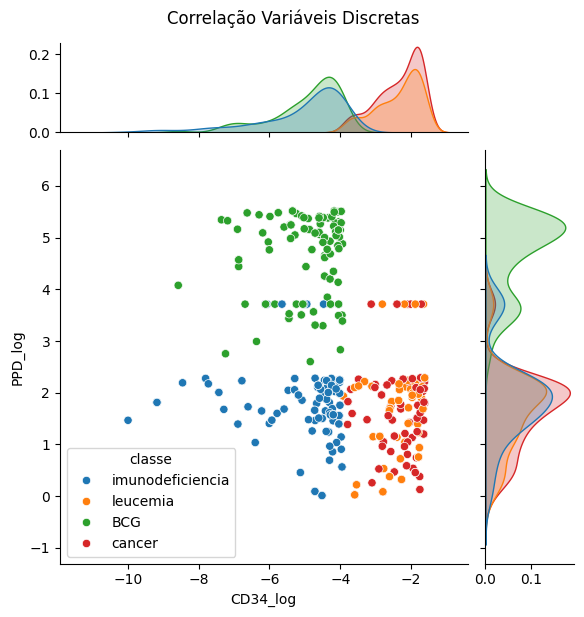

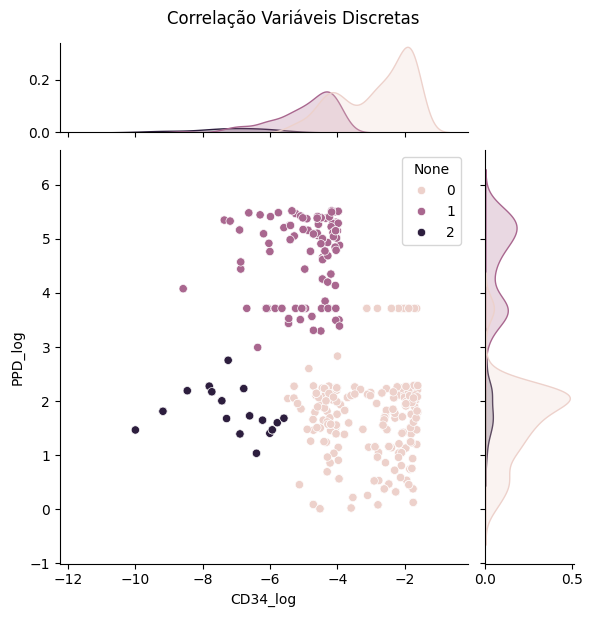

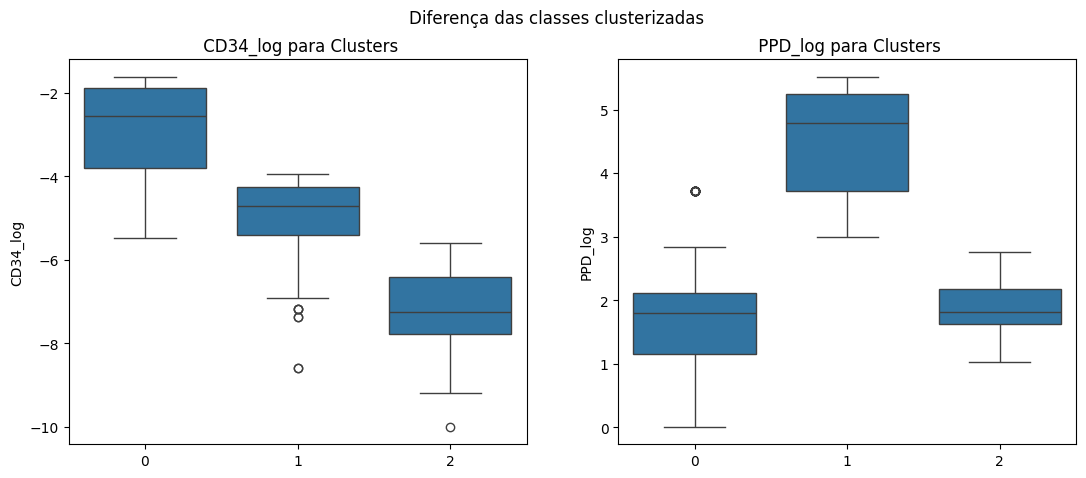

In [ ]:
#CD34_log e PPD_log IDENTIFICA 3 GRUPOS - RETIRAR
i = bivariadas[0][0]
j = bivariadas[1][0]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.5532

Silhouette Score -> 0.55
Calinski Harabasz Score -> 982.863
Davies Bouldin Score -> 0.676
Adjusted Rand Score -> 0.663
Adjusted Mutual Info Score -> 0.755


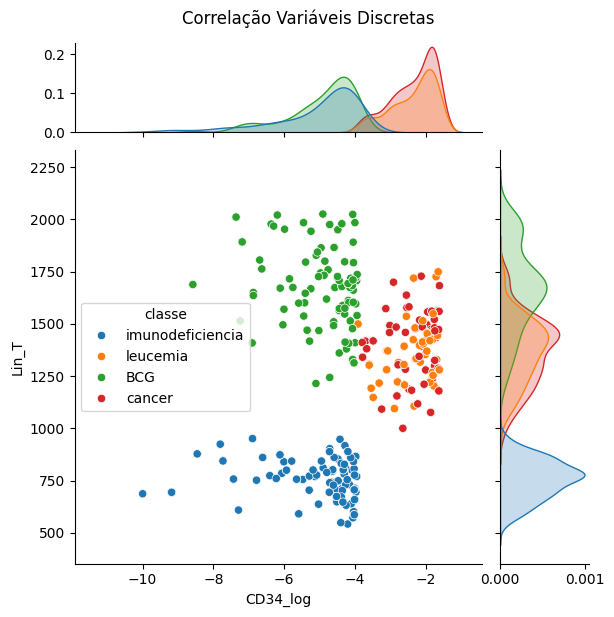

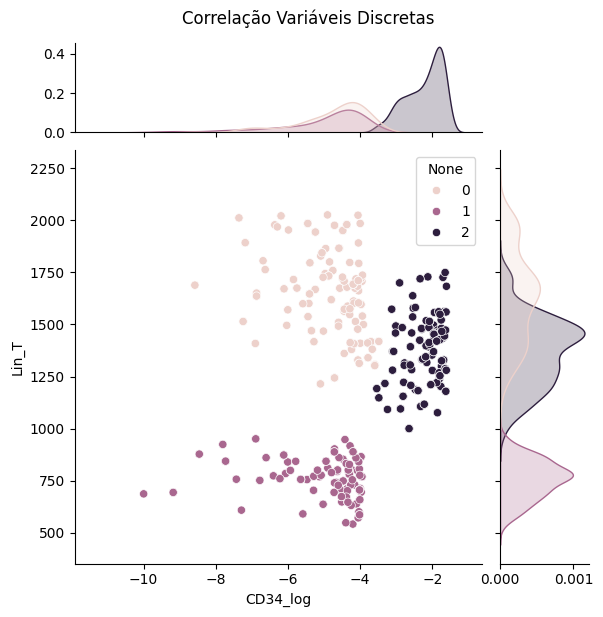

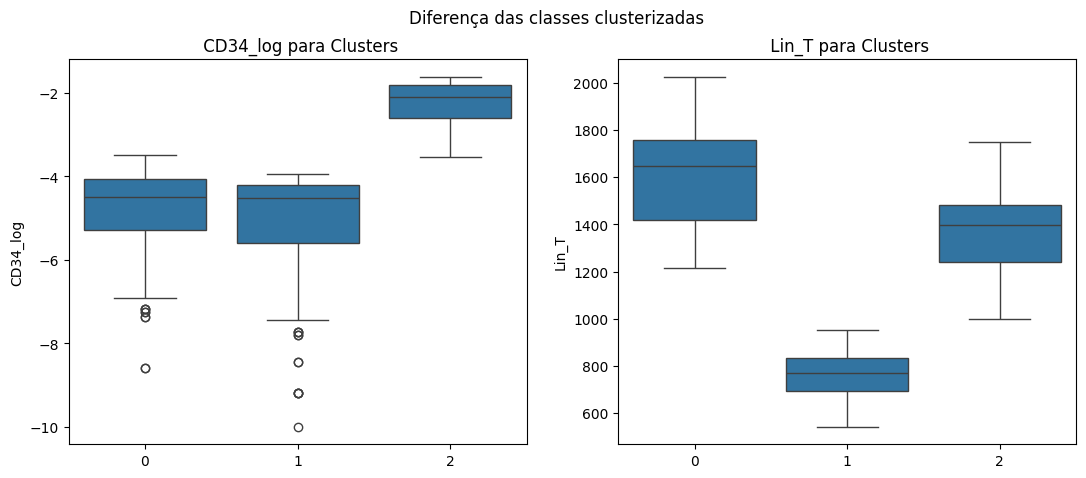

In [ ]:
#CD34_log e Lin_T IDENTIFICA 3 GRUPOS - RETIRAR
i = bivariadas[0][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.7053

Silhouette Score -> 0.705
Calinski Harabasz Score -> 2195.319
Davies Bouldin Score -> 0.428
Adjusted Rand Score -> 0.322
Adjusted Mutual Info Score -> 0.568


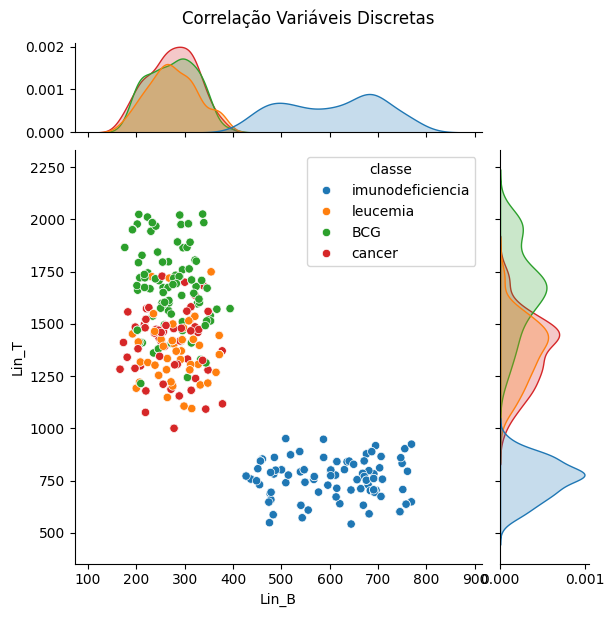

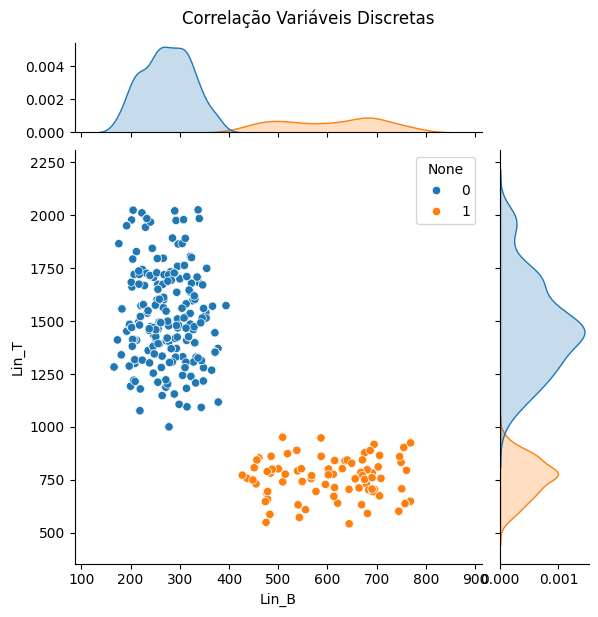

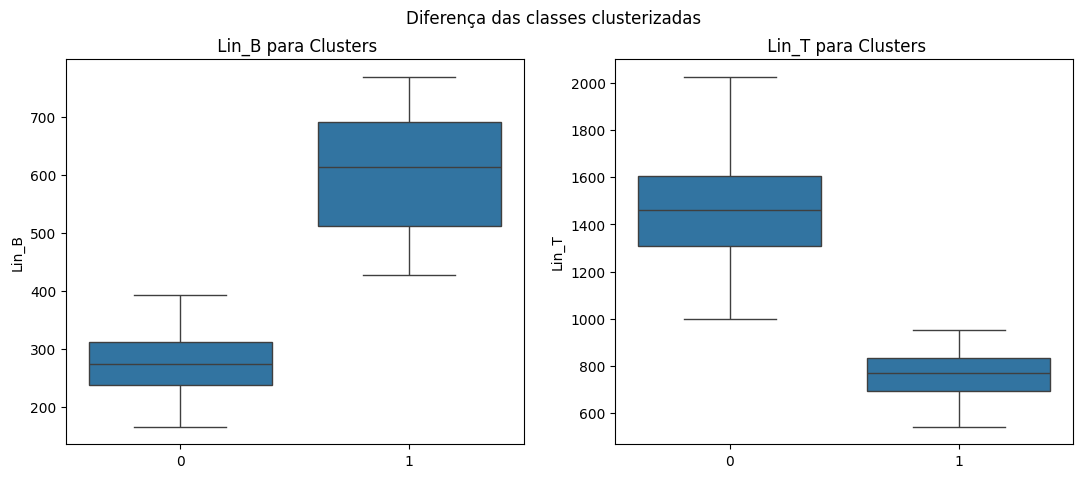

In [ ]:
#CD34_log e Lin_T IDENTIFICA 2 GRUPOS - RETIRAR
i = bivariadas[0][1]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.5596

Silhouette Score -> 0.548
Calinski Harabasz Score -> 739.271
Davies Bouldin Score -> 0.719
Adjusted Rand Score -> 0.306
Adjusted Mutual Info Score -> 0.535


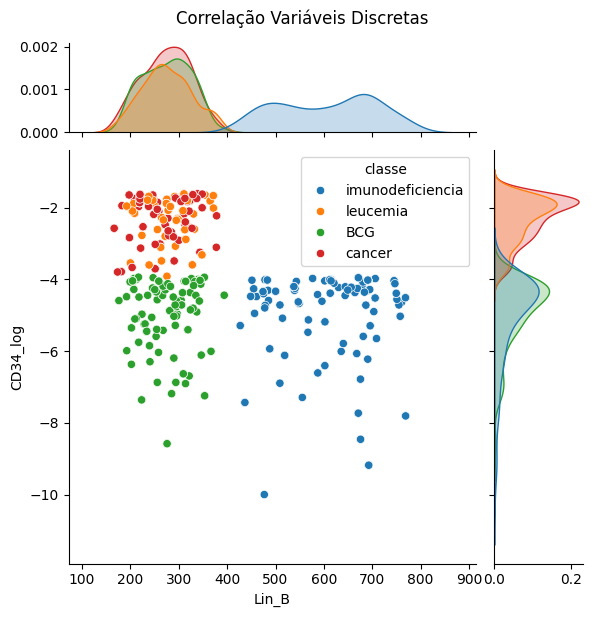

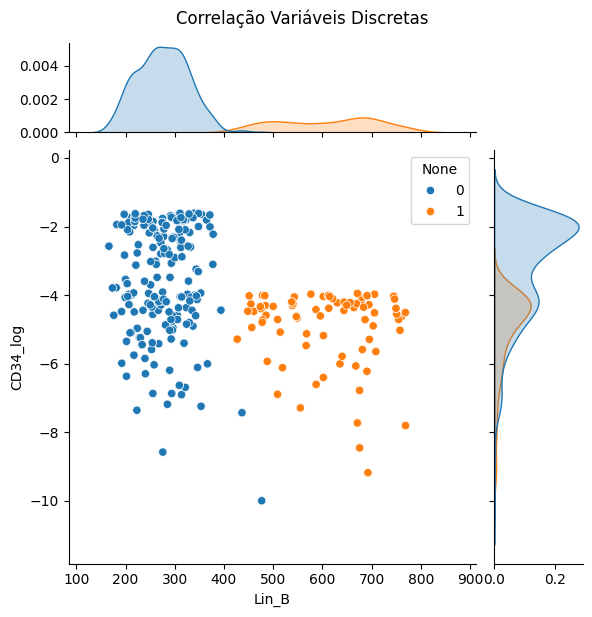

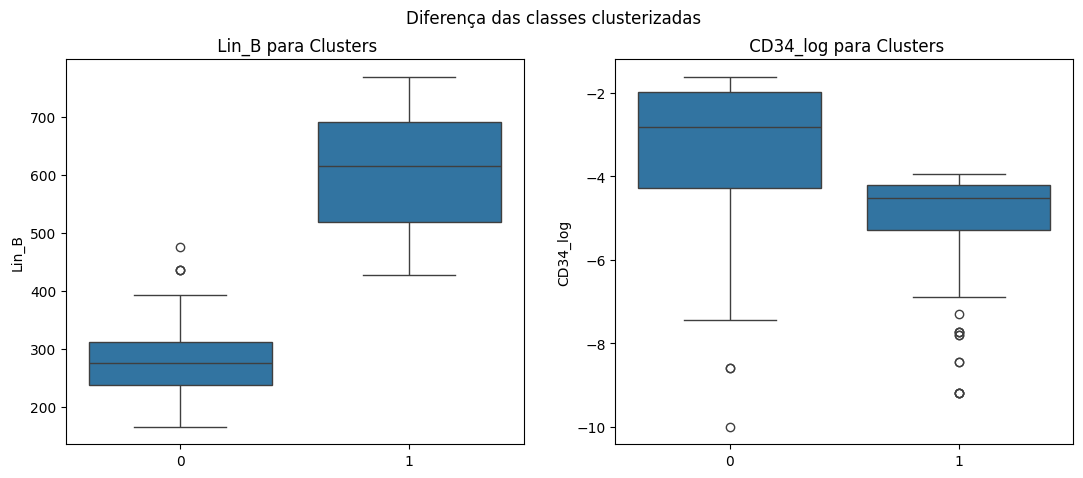

In [ ]:
#CD34_log e Lin_T IDENTIFICA 2 GRUPOS - Retirar
i = bivariadas[0][1]
j = bivariadas[0][0]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.6000

Silhouette Score -> 0.596
Calinski Harabasz Score -> 1329.208
Davies Bouldin Score -> 0.568
Adjusted Rand Score -> 0.666
Adjusted Mutual Info Score -> 0.759


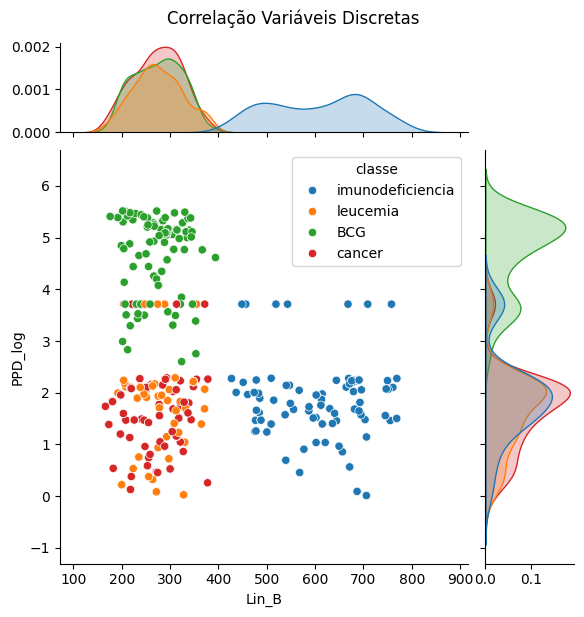

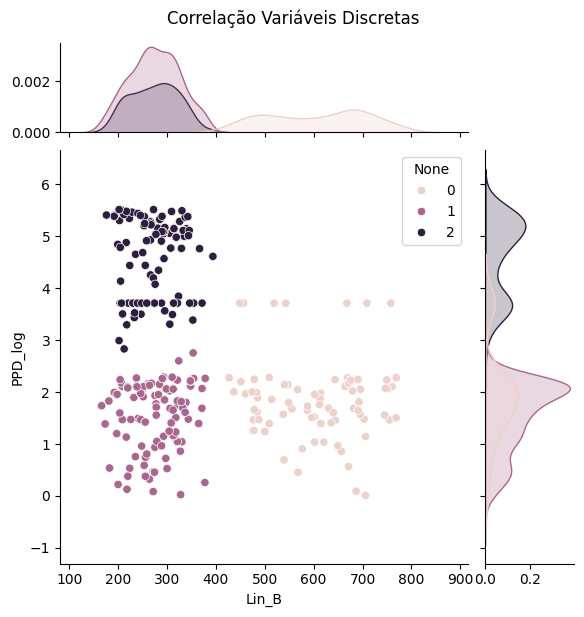

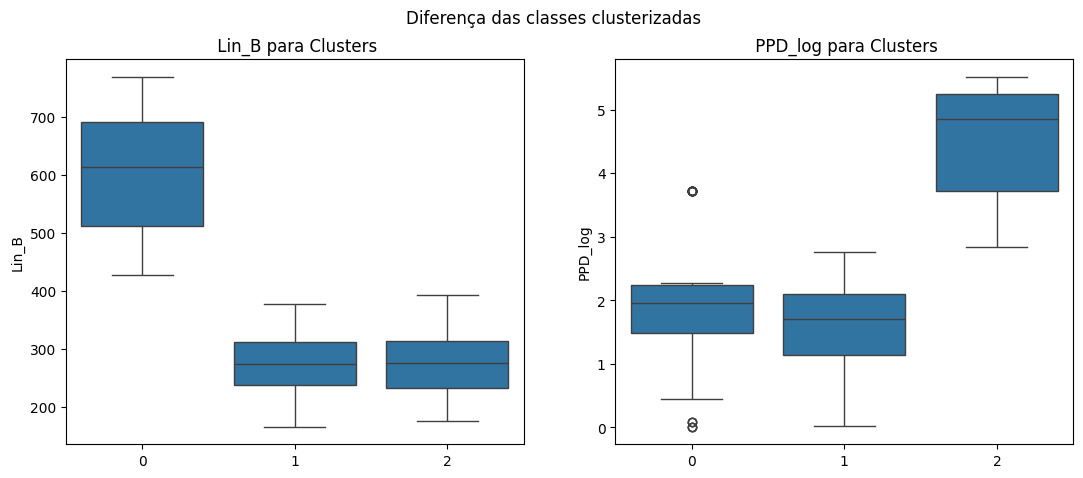

In [ ]:
1#PPD_log e Lin_B IDENTIFICA 3 GRUPOS - Retirar
i = bivariadas[0][1]
j = bivariadas[1][0]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis
data = {}
for i in df_train.columns[:-1]:
    for j in df_train.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas_agglomerative_train = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_agglomerative_train.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
CD34_log_Lin_B,0.548,739.271,0.719,0.306,0.535
CD34_log_Lin_T,0.550,982.863,0.676,0.663,0.755
CD34_log_PPD_log,0.548,740.356,0.607,0.344,0.499
Lin_B_CD34_log,0.548,739.271,0.719,0.306,0.535
Lin_B_Lin_T,0.705,2195.319,0.428,0.322,0.568


In [ ]:
# Selecionando as melhores combinações de variáveis com base nas métricas de
# avaliação de clustering
display(df_metricas_agglomerative_train["Silhouette"].nlargest(1))
display(df_metricas_agglomerative_train["Calinski Harabasz"].nsmallest(1))
display(df_metricas_agglomerative_train["Davies Bouldin"].nlargest(1))
display(df_metricas_agglomerative_train["Adjusted Rand"].nlargest(1))
display(df_metricas_agglomerative_train["Adjusted Mutual Info"].nlargest(1))

Lin_B_Lin_T    0.705
Name: Silhouette, dtype: float64

CD34_log_Lin_B    739.271
Name: Calinski Harabasz, dtype: float64

CD34_log_Lin_B    0.719
Name: Davies Bouldin, dtype: float64

Lin_B_PPD_log    0.666
Name: Adjusted Rand, dtype: float64

Lin_B_PPD_log    0.759
Name: Adjusted Mutual Info, dtype: float64

Utilizaremos as variáveis associadas a melhores métricas -> Lin_B, Lin_T e CD34_log, as mesmas 3 selecionadas nos outros 2 metodos

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# CD43_log e Lin_B, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="CD34_log", c2="Lin_B", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_train_agg = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_train_agg.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.548,739.271,0.719,0.306,0.535
1,0.548,739.271,0.719,0.306,0.535
2,0.548,739.271,0.719,0.306,0.535
3,0.548,739.271,0.719,0.306,0.535
4,0.548,739.271,0.719,0.306,0.535


In [ ]:
dump(df_metricas_repeti_train_agg, './Metricas Agglomerative/df_metricas_repeti_trainCD34_log_Lin_B_agg')

['./Metricas Agglomerative/df_metricas_repeti_trainCD34_log_Lin_B_agg']

In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti_train_agg = df_metricas_repeti_train_agg.describe()

In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|{df_metricas_repeti_train_agg['Silhouette'][1]}|   
|Silhouette_sd|{df_metricas_repeti_train_agg['Silhouette'][2]}|   
|Calinski Harabasz_mean|{df_metricas_repeti_train_agg['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{df_metricas_repeti_train_agg['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{df_metricas_repeti_train_agg['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{df_metricas_repeti_train_agg['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{df_metricas_repeti_train_agg['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{df_metricas_repeti_train_agg['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{df_metricas_repeti_train_agg['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{df_metricas_repeti_train_agg['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1797140640.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_mean|{df_metricas_repeti_train_agg['Silhouette'][1]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1797140640.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_sd|{df_metricas_repeti_train_agg['Silhouette'][2]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1797140640.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value


|Métrica|Métricas Treino|
|-|-|     
|Silhouette_mean|0.5480000000000002|   
|Silhouette_sd|1.1158161231197418e-16|   
|Calinski Harabasz_mean|739.2709999999996|
|Calinski Harabasz_sd|3.427787130223847e-13|
|Davies Bouldin_mean|0.7189999999999999|
|Davies Bouldin_sd|1.1158161231197418e-16|
|Adjusted Rand_mean|0.30600000000000005|
|Adjusted Rand_sd|5.579080615598709e-17|
|Adjusted Mutual Info_mean|0.5349999999999999|
|Adjusted Mutual Info_sd|1.1158161231197418e-16|



### Validação

In [ ]:
# Importando os dados de validação
df_valid = pd.concat(
    [
        load("./df_trabalho_X_valid"),
        load("./df_trabalho_y_valid"),
    ],
    axis=1,
)
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
904,-4.354233,683.860757,702.521323,2.228345,True,False,False,True,False,True,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,False,True,True,False,False,True,leucemia
139,-2.771307,223.769444,1315.554814,0.532531,False,True,True,False,False,True,cancer
526,-1.810700,364.827049,1268.215382,1.394407,False,True,True,False,False,True,cancer
868,-2.473679,271.804503,1187.576700,0.468055,False,True,True,False,False,True,cancer


In [ ]:
df_valid = df_valid[['CD34_log', 'Lin_B', 'Lin_T', 'classe']]

Aplicando o cross-validation 100x para o par CD34_log e Lin_B, analisado para os passos de treino e nos modelos anteriores

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# CD34_log e Lin_B, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(
        c1='CD34_log', c2='Lin_B', df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_agg = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_agg.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.555,326.401,0.663,0.687,0.802
1,0.555,326.401,0.663,0.687,0.802
2,0.555,326.401,0.663,0.687,0.802
3,0.555,326.401,0.663,0.687,0.802
4,0.555,326.401,0.663,0.687,0.802


In [ ]:
dump(df_metricas_repeti_valid_agg, './Metricas Agglomerative/df_metricas_repeti_validCD34_log_Lin_B_agg')

['./Metricas Agglomerative/df_metricas_repeti_validCD34_log_Lin_B_agg']

In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti_valid_agg =df_metricas_repeti_valid_agg.describe()

Comparativo de métricas de treino e validação

In [ ]:
mensagem = f'''
|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|{df_metricas_repeti_train_agg['Silhouette'][1]}|{df_metricas_repeti_valid_agg['Silhouette'][1]}|   
|Silhouette_sd|{df_metricas_repeti_train_agg['Silhouette'][2]}|{df_metricas_repeti_valid_agg['Silhouette'][2]}|   
|Calinski Harabasz_mean|{df_metricas_repeti_train_agg['Calinski Harabasz'][1]}|{df_metricas_repeti_valid_agg['Calinski Harabasz'][1]}|
|Calinski Harabasz_sd|{df_metricas_repeti_train_agg['Calinski Harabasz'][2]}|{df_metricas_repeti_valid_agg['Calinski Harabasz'][2]}|
|Davies Bouldin_mean|{df_metricas_repeti_train_agg['Davies Bouldin'][1]}|{df_metricas_repeti_valid_agg['Davies Bouldin'][1]}|
|Davies Bouldin_sd|{df_metricas_repeti_train_agg['Davies Bouldin'][2]}|{df_metricas_repeti_valid_agg['Davies Bouldin'][2]}|
|Adjusted Rand_mean|{df_metricas_repeti_train_agg['Adjusted Rand'][1]}|{df_metricas_repeti_valid_agg['Adjusted Rand'][1]}|
|Adjusted Rand_sd|{df_metricas_repeti_train_agg['Adjusted Rand'][2]}|{df_metricas_repeti_valid_agg['Adjusted Rand'][2]}|
|Adjusted Mutual Info_mean|{df_metricas_repeti_train_agg['Adjusted Mutual Info'][1]}|{df_metricas_repeti_valid_agg['Adjusted Mutual Info'][1]}|
|Adjusted Mutual Info_sd|{df_metricas_repeti_train_agg['Adjusted Mutual Info'][2]}|{df_metricas_repeti_valid_agg['Adjusted Mutual Info'][2]}|

'''

display(Markdown(mensagem))

C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1469221126.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_mean|{df_metricas_repeti_train_agg['Silhouette'][1]}|{df_metricas_repeti_valid_agg['Silhouette'][1]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1469221126.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  |Silhouette_sd|{df_metricas_repeti_train_agg['Silhouette'][2]}|{df_metricas_repeti_valid_agg['Silhouette'][2]}|
C:\Users\sofia\AppData\Local\Temp\ipykernel_146292\1469221126.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integ


|Métrica|Métricas Treino|Métricas Validação|
|-|-|-|     
|Silhouette_mean|0.5480000000000002|0.5549999999999999|   
|Silhouette_sd|1.1158161231197418e-16|1.1158161231197418e-16|   
|Calinski Harabasz_mean|739.2709999999996|326.401|
|Calinski Harabasz_sd|3.427787130223847e-13|0.0|
|Davies Bouldin_mean|0.7189999999999999|0.6630000000000001|
|Davies Bouldin_sd|1.1158161231197418e-16|1.1158161231197418e-16|
|Adjusted Rand_mean|0.30600000000000005|0.687|
|Adjusted Rand_sd|5.579080615598709e-17|0.0|
|Adjusted Mutual Info_mean|0.5349999999999999|0.802|
|Adjusted Mutual Info_sd|1.1158161231197418e-16|0.0|



# Analisando métricas validação

In [ ]:
# Salvando os dataframes de métricas de avaliação de clustering para cada
# algoritmo

# K-means
local = "./Metricas Kmeans/df_metricas_repeti_validCD34_log_LinB_kmeans"
df_metricas_repeti_valid_kmeans = load(local)
df_metricas_repeti_valid_kmeans["algoritmo"] = "kmeans"
print("K-means")
display(df_metricas_repeti_valid_kmeans.head())

# DBSCAN
local = "./Metricas DBscan/df_metricas_repeti_validCD34_log_LinB_dbscan"
df_metricas_repeti_valid_dbscan = load(local)
df_metricas_repeti_valid_dbscan["algoritmo"] = "dbscan"
print("DBSCAN")
display(df_metricas_repeti_valid_dbscan.head())

# Agrupamento Hierárquico (Agglomerative)
local = "./Metricas Agglomerative/df_metricas_repeti_validCD34_log_Lin_B_agg"
df_metricas_repeti_valid_agg = load(local)
df_metricas_repeti_valid_agg["algoritmo"] = "agg"
print("Agglomerative")
display(df_metricas_repeti_valid_agg.head())



K-means


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.555,326.401,0.663,0.687,0.802,kmeans
1,0.555,326.401,0.663,0.687,0.802,kmeans
2,0.555,326.401,0.663,0.687,0.802,kmeans
3,0.555,326.401,0.663,0.687,0.802,kmeans
4,0.555,326.401,0.663,0.687,0.802,kmeans


DBSCAN


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.555,326.401,0.663,0.687,0.802,dbscan
1,0.555,326.401,0.663,0.687,0.802,dbscan
2,0.555,326.401,0.663,0.687,0.802,dbscan
3,0.555,326.401,0.663,0.687,0.802,dbscan
4,0.555,326.401,0.663,0.687,0.802,dbscan


Agglomerative


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.555,326.401,0.663,0.687,0.802,agg
1,0.555,326.401,0.663,0.687,0.802,agg
2,0.555,326.401,0.663,0.687,0.802,agg
3,0.555,326.401,0.663,0.687,0.802,agg
4,0.555,326.401,0.663,0.687,0.802,agg


In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os
# três algoritmos
df_metricas = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=0,
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.555,326.401,0.663,0.687,0.802,kmeans
1,0.555,326.401,0.663,0.687,0.802,kmeans
2,0.555,326.401,0.663,0.687,0.802,kmeans
3,0.555,326.401,0.663,0.687,0.802,kmeans
4,0.555,326.401,0.663,0.687,0.802,kmeans


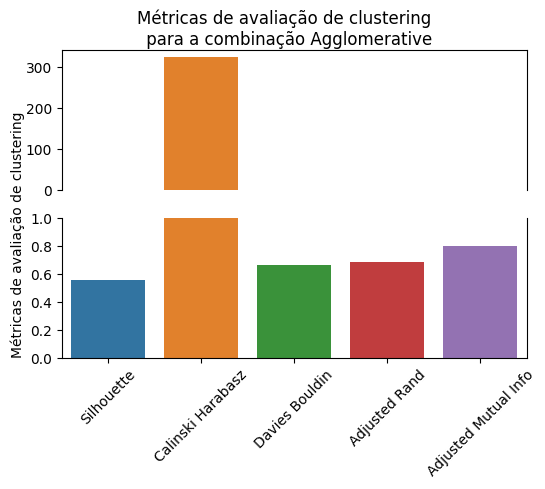

In [ ]:
# Gráfico comparativo das métricas de avaliação de clustering para os três
# algoritmos
fig, ax = plt.subplots(2, 1, figsize=(6, 4))

plt.suptitle("Métricas de avaliação de clustering \n para a combinação Agglomerative")

p = sns.barplot(df_metricas_repeti_valid_agg, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)

q = sns.barplot(df_metricas_repeti_valid_agg, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(False)

plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
df_metricas2 = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=1,
    keys=["kmeans", "dbscan", "agglomerative"],
)
df_metricas2.head()

kmeans                                                 \
  Silhouette Calinski Harabasz Davies Bouldin Adjusted Rand   
0      0.555           326.401          0.663         0.687   
1      0.555           326.401          0.663         0.687   
2      0.555           326.401          0.663         0.687   
3      0.555           326.401          0.663         0.687   
4      0.555           326.401          0.663         0.687   

                                     dbscan                                   \
  Adjusted Mutual Info algoritmo Silhouette Calinski Harabasz Davies Bouldin   
0                0.802    kmeans      0.555           326.401          0.663   
1                0.802    kmeans      0.555           326.401          0.663   
2                0.802    kmeans      0.555           326.401          0.663   
3                0.802    kmeans      0.555           326.401          0.663   
4                0.802    kmeans      0.555           326.401          0.663   

                                               agglomerative  \
  Adjusted Rand Adjusted Mutual Info algoritmo    Silhouette   
0         0.687                0.802    dbscan         0.555   
1         0.687                0.802    dbscan         0.555   
2         0.687                0.802    dbscan         0.555   
3         0.687                0.802    dbscan         0.555   
4         0.687                0.802    dbscan         0.555   

                                                                       \
  Calinski Harabasz Davies Bouldin Adjusted Rand Adjusted Mutual Info   
0           326.401          0.663         0.687                0.802   
1           326.401          0.663         0.687                0.802   
2           326.401          0.663         0.687                0.802   
3           326.401          0.663         0.687                0.802   
4           326.401          0.663         0.687                0.802   

             
  algoritmo  
0       agg  
1       agg  
2       agg  
3       agg  
4       agg

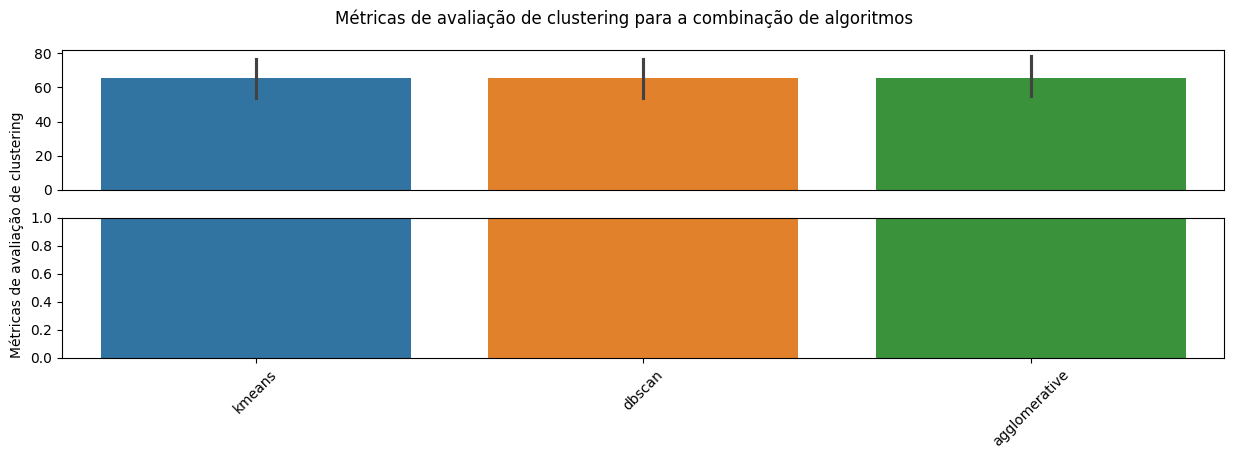

In [ ]:
# Gráfico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a combinação de algoritmos")

p = sns.barplot(df_metricas2, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(True)

q = sns.barplot(df_metricas2, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(True)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [ ]:
def editar_df(df: pd.DataFrame, modelo: str) -> pd.DataFrame:
    """
    Função para editar o dataframe de métricas de avaliação de clustering
    para cada algoritmo, de forma a facilitar a análise comparativa entre
    eles.
        Parametros:
        -----------
            df: pd.DataFrame
                Dataframe de métricas de avaliação de clustering para
                cada algoritmo.
            modelo: str
                Nome do algoritmo de clustering.
        Retorna:
            pd.DataFrame
    """
    colunas = {0: "valores", "index": "metricas"}
    retorno = (
        df.select_dtypes(include="number")
        .median()
        .to_frame()
        .reset_index()
        .rename(columns=colunas)
        .assign(modelo=modelo)
    )
    return retorno

In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas

df_metricas = pd.concat(
    (
        editar_df(df=df_metricas_repeti_valid_kmeans, modelo="K-means"),
        editar_df(df=df_metricas_repeti_valid_dbscan, modelo="DBSCAN"),
        editar_df(df=df_metricas_repeti_valid_agg, modelo="Agglomerative"),
    )
)
df_metricas

,metricas,valores,modelo
0,Silhouette,0.555,K-means
1,Calinski Harabasz,326.401,K-means
2,Davies Bouldin,0.663,K-means
3,Adjusted Rand,0.687,K-means
4,Adjusted Mutual Info,0.802,K-means
0,Silhouette,0.555,DBSCAN
1,Calinski Harabasz,326.401,DBSCAN
2,Davies Bouldin,0.663,DBSCAN
3,Adjusted Rand,0.687,DBSCAN
4,Adjusted Mutual Info,0.802,DBSCAN


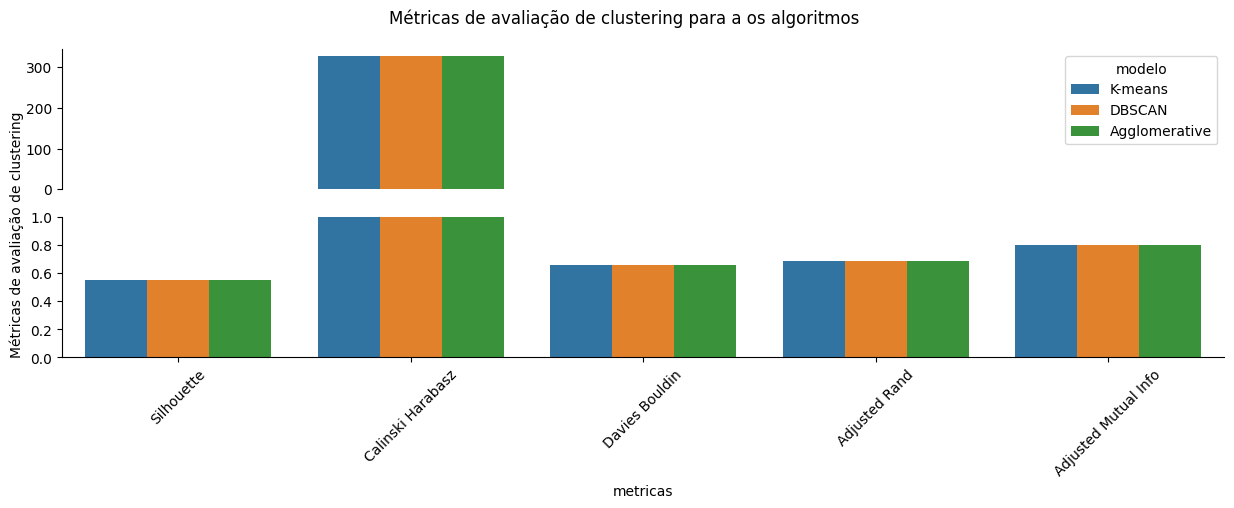

In [ ]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

q = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

# Testes

__Teste Qui-Quadrado de Aderência/Independência__:
- Teste de Proporções dos Clusters: Avalia se a distribuição de frequência de pontos por cluster é idêntica entre treino (700) e validação (100).

__Adjusted Rand Index__:
- Avaliação da Estrutura de Rotulagem (Cross-Prediction ou Teste de Permutação): Avalia se o modelo fitado no treino atribui aos dados de validação os mesmos rótulos que um modelo fitado diretamente na validação atribuiria.

|Hipótese|Interpretação|
|-|-|
|H0 - Hipótese Nula|A distribuição de clusters na teste é igual à do treino. O modelo generalizou bem.|
H1 - Hipótese Alternativa|A distribuição de clusters na teste é diferente da do treino. Houve data drift ou mudança de padrão.|

In [ ]:
from scipy.stats import chisquare
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.metrics import adjusted_rand_score

## Importando dados de teste

In [ ]:
# Importando os dados de treino
df_test = pd.concat(
    [
        load("./df_trabalho_X_test"),
        load("./df_trabalho_y_test"),
    ],
    axis=1,
)
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
557,-3.243291,343.587918,1092.448432,1.478703,False,True,True,False,False,True,cancer
798,-2.082097,308.565265,1514.927999,1.406982,False,True,True,False,False,True,leucemia
977,-2.154434,208.457031,1317.570437,2.114693,False,True,True,False,False,True,cancer
136,-2.780156,279.316121,1304.394062,1.050797,False,True,True,False,False,True,cancer
575,-4.625737,547.067973,802.296876,2.145163,True,False,False,True,False,True,imunodeficiencia


In [ ]:
# Retornaod dados de treino
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,classe
541,-6.605859,587.422573,861.125119,1.728509,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,leucemia
422,-4.197952,537.954188,889.391214,1.574182,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,leucemia


## Teste para a combinação CD34_log e Lin_B

>>  K-means

In [ ]:
bivariadas = [
    ["CD34_log", "Lin_B"],
    ["Lin_T", "PPD_log"],
]


In [ ]:
# Testando os modelos de clustering via K-means
resultados = {}
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
    resultados[f"K-means: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 3, "init": "k-means++", "n_init": 10},
        df_test=df_test,
    )

CD34_log Lin_B ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação (Treino): 
[10.42857143 75.85714286 13.71428571]
Frequências Observadas na Validação:
       [17 69 14]
--------------------------------------------------
Estatística Qui-Quadrado (χ²): 4.7667
p-valor:                        0.0922
--------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
--------------------------------------------------
Adjusted Rand Index (ARI) entre modelo de Treino e modelo da Validação: 0.8779 (ARI próximo de 1.0 indica que a partição geométrica gerada é virtualmente idêntica)
Lin_T PPD_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação 

>> DBSCAN

In [ ]:
# Testando os modelos de clustering via DBSCAN
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="dbscan")
    resultados[f"DBSCAN: {i}/{j}"] = cluster.testar_modelo(
        best_param={"eps": 0.5, "min_samples": 10, "metric": "euclidean"},
        df_test=df_test,
    )

CD34_log Lin_B ----------------------------------------------------------------------------------------------------


 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[-1  0  1  2]
Frequências Esperadas na Validação:     
[95.43  1.43  1.43  1.71]
Frequências Observadas na Validação:    
[98  0  0  2]
-------------------------------------------------------
Estatística Qui-Quadrado (χ²): 2.9741
p-valor:                        0.3956
-------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters
na validação É IGUAL à do treino (p > 0.05).
-------------------------------------------------------
Adjusted Rand Index (ARI) entre predição e DBSCAN direto na Validação: 0.0000
Lin_T PPD_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[-1  0  1]
Frequências Esperadas na Validação:     
[96.86  1.43  1.71]
Frequências Observadas na Validação:    
[98  1  1]
-----------------------

>> Agrupamento Hierarquico

In [ ]:
# Testando os modelos de clustering via Agrupamento Hierarquico
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="agglomerative")
    resultados[f"Agg: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 2, "metric": "euclidean", "linkage": "average"},
        df_test=df_test,
    )

CD34_log Lin_B ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[23.86 76.14]
Frequências Observadas na Validação:  
[28 72]
------------------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.9448
p-valor:                        0.3310
------------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
------------------------------------------------------------
Adjusted Rand Index (ARI) entre projeção e agrupamento direto: 1.0000
Lin_T PPD_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[75.4

>Mesmo teste para as demais combinações de variáveis

## Resultado Final

In [ ]:
pip install util

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
ut.printDic(resultados)

NameError: name 'ut' is not defined